In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#base = "/glade/work/jcelis/code/jcelis/2.mobility_code/POI_analysis/POIs_output_v3/supermarket_baseline_rg0_All"
base= "/glade/work/jcelis/code/jcelis/2.mobility_code/POI_analysis/POIs_output_v5_05march2026/supermarket_baseline_rg0_All"
matched = pd.read_parquet(f"{base}/matched_stays_with_poi_latlon.parquet")
hourly  = pd.read_parquet(f"{base}/hourly_with_poi_latlon.parquet")
daily   = pd.read_parquet(f"{base}/daily_with_poi_latlon.parquet")

In [8]:
print(matched.head())
print(hourly.head())
print(daily.head())

print(matched.columns)
print(hourly.columns)
print(daily.columns)

                                                 uid  \
0  00005e187c8f780daec096cc826af547363df7ad5ed888...   
1  000093ca81930e1c247112fceaa58e2d2e3df3e1d438f6...   
2  0000c324d3faf46d7cecdd2ff978b0364a37ca1b6cab18...   
3  0000c4f1622a043a14ff5ab51aed9833409c8867f227aa...   
4  000113ce3330cb882b58599914da21cdc3f0519a1c2381...   

                   datetime          leaving_datetime  duration_min  \
0 2024-03-23 10:30:33-07:00 2024-03-23 10:49:32-07:00     18.983333   
1 2024-03-24 13:08:36-07:00 2024-03-24 13:20:44-07:00     12.133333   
2 2024-04-26 11:46:00-07:00 2024-04-26 18:39:49-07:00    413.816667   
3 2024-04-28 15:34:44-07:00 2024-04-28 16:40:26-07:00     65.700000   
4 2024-03-28 19:27:01-07:00 2024-03-28 22:50:50-07:00    203.816667   

        poi_id     poi_type       county    poi_lat     poi_lon         day  
0   8994258716  supermarket  Los Angeles  34.048743 -118.344038  2024-03-23  
1  11663856411  supermarket  Los Angeles  34.107492 -117.836444  2024-03-24  
2 

In [43]:
print(matched.head())


                                                 uid            datetime  \
0  00005e187c8f780daec096cc826af547363df7ad5ed888... 2024-03-23 10:30:33   
1  000093ca81930e1c247112fceaa58e2d2e3df3e1d438f6... 2024-03-24 13:08:36   
2  0000c324d3faf46d7cecdd2ff978b0364a37ca1b6cab18... 2024-04-26 11:46:00   
3  0000c4f1622a043a14ff5ab51aed9833409c8867f227aa... 2024-04-28 15:34:44   
4  000113ce3330cb882b58599914da21cdc3f0519a1c2381... 2024-03-28 19:27:01   

           leaving_datetime  duration_min       poi_id     poi_type  \
0 2024-03-23 10:49:32-07:00     18.983333   8994258716  supermarket   
1 2024-03-24 13:20:44-07:00     12.133333  11663856411  supermarket   
2 2024-04-26 18:39:49-07:00    413.816667   1932402430  supermarket   
3 2024-04-28 16:40:26-07:00     65.700000  11989079604  supermarket   
4 2024-03-28 22:50:50-07:00    203.816667   1897562819  supermarket   

        county    poi_lat     poi_lon        day  hour  
0  Los Angeles  34.048743 -118.344038 2024-03-23    10  
1 

In [9]:
print("Total visits:", len(matched))

Total visits: 172205


In [10]:
list(matched.columns)

['uid',
 'datetime',
 'leaving_datetime',
 'duration_min',
 'poi_id',
 'poi_type',
 'county',
 'poi_lat',
 'poi_lon',
 'day']

In [11]:
print("Total visits:", len(matched))
print("Unique devices:", matched["uid"].nunique())
print("Unique POIs:", matched["poi_id"].nunique())
print("Avg dwell (minutes):", matched["duration_min"].mean())
print("Median dwell (minutes):", matched["duration_min"].median())

Total visits: 172205
Unique devices: 102245
Unique POIs: 583
Avg dwell (minutes): 108.31839248676478
Median dwell (minutes): 35.583333333333336


In [12]:
visits_per_poi = (
    matched.groupby("poi_id")
    .agg(
        visits=("uid","count"),
        unique_devices=("uid","nunique"),
        avg_dwell=("duration_min","mean"),
        total_dwell=("duration_min","sum")
    )
    .sort_values("visits", ascending=False)
)

visits_per_poi.head(20)

,visits,unique_devices,avg_dwell,total_dwell
poi_id,,,,
6069801685,1932,1304,124.829449,241170.494917
12252186751,1495,1110,114.612734,171346.037883
9291373845,1495,726,115.544395,172738.870567
608957448,1414,1111,115.596564,163453.541900
4399334440,1401,775,112.156704,157131.542400
4768262526,1325,806,118.469879,156972.589333
9658410708,1325,887,131.897675,174764.419233
3507799463,1152,703,105.566618,121612.744333
805610612,1094,585,118.452235,129586.745350


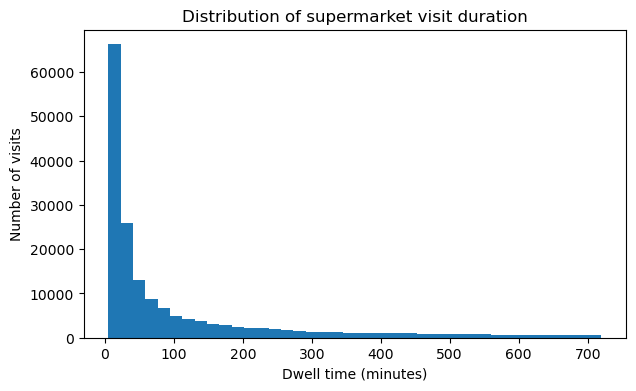

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))

plt.hist(matched["duration_min"], bins=40)

plt.xlabel("Dwell time (minutes)")
plt.ylabel("Number of visits")
plt.title("Distribution of supermarket visit duration")

plt.show()

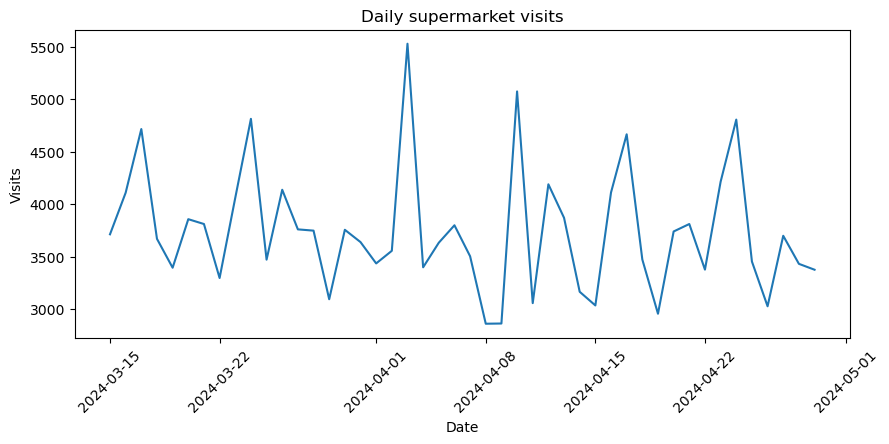

In [13]:
matched["day"] = matched["datetime"].dt.date

daily_visits = matched.groupby("day")["uid"].count()

plt.figure(figsize=(10,4))

plt.plot(daily_visits.index, daily_visits.values)

plt.xlabel("Date")
plt.ylabel("Visits")
plt.title("Daily supermarket visits")

plt.xticks(rotation=45)

plt.show()
#hourly on the 30th. Day raining compared to hourly on 23rd/ all five saturdays. 

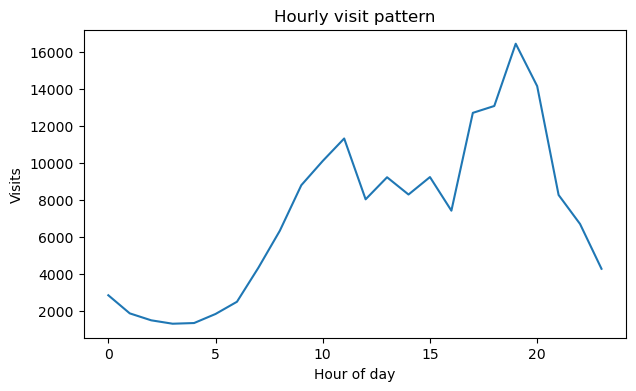

In [14]:
matched["hour"] = matched["datetime"].dt.hour

hourly_visits = matched.groupby("hour")["uid"].count()

plt.figure(figsize=(7,4))

plt.plot(hourly_visits.index, hourly_visits.values)

plt.xlabel("Hour of day")
plt.ylabel("Visits")
plt.title("Hourly visit pattern")

plt.show()

In [19]:
poi_stats = (
    matched.groupby(["poi_id","poi_lat","poi_lon"])
    .size()
    .reset_index(name="visits")
)

m = folium.Map(
    location=[poi_stats["poi_lat"].mean(), poi_stats["poi_lon"].mean()],
    zoom_start=6
)

for _, row in poi_stats.iterrows():
    
    folium.CircleMarker(
        location=[row["poi_lat"], row["poi_lon"]],
        radius=2 + row["visits"]/10,
        color="darkred",
        fill=True,
        fill_opacity=0.7,
        popup=f"Visits: {row['visits']}"
    ).add_to(m)

m

In [18]:
import glob
import folium

# Visuals for analysis

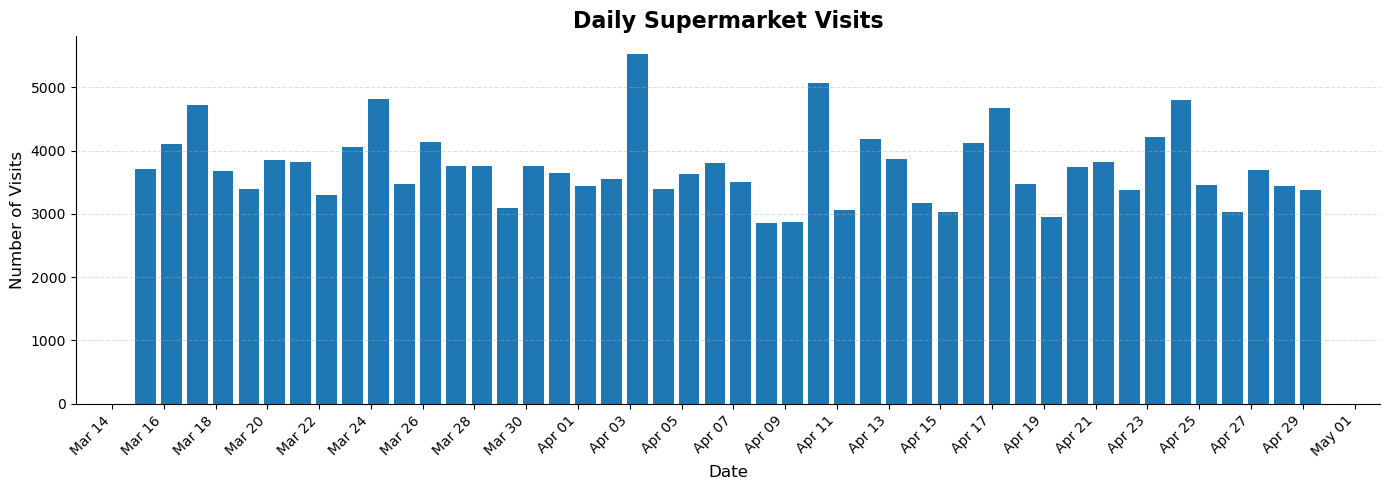

In [20]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

matched["day"] = pd.to_datetime(matched["datetime"]).dt.floor("D")
daily_visits = matched.groupby("day")["uid"].count().sort_index()

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(daily_visits.index, daily_visits.values, width=0.8)

ax.set_title("Daily Supermarket Visits", fontsize=16, weight="bold")
ax.set_ylabel("Number of Visits", fontsize=12)
ax.set_xlabel("Date", fontsize=12)

# cleaner date labels
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))  # change to 1 if you want every day shown
plt.xticks(rotation=45, ha="right")

# clean up chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

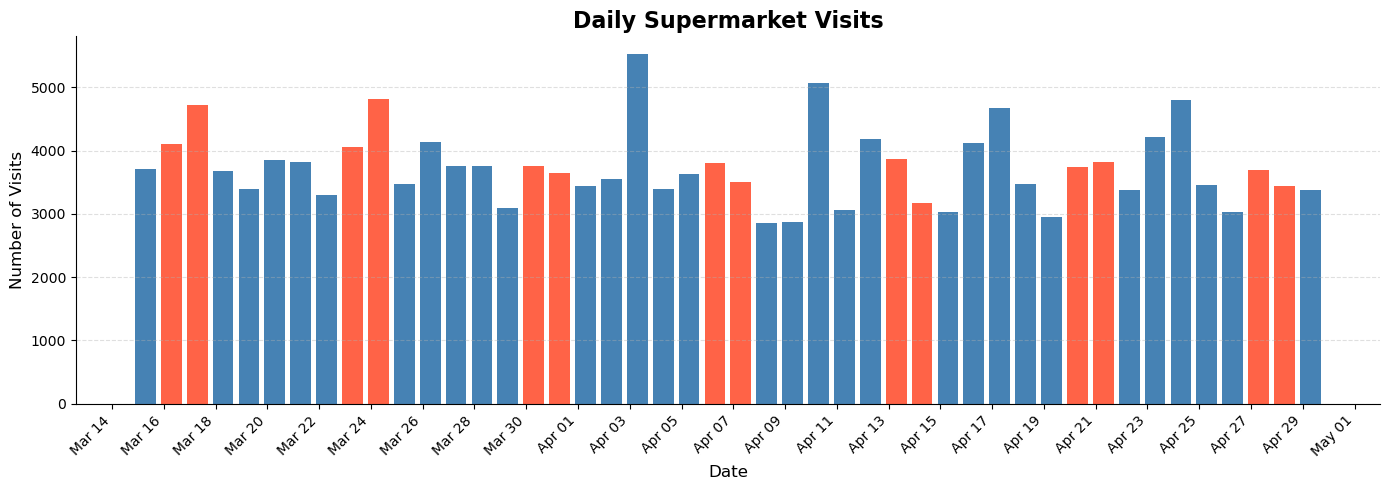

In [21]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

matched["day"] = pd.to_datetime(matched["datetime"]).dt.floor("D")
daily_visits = matched.groupby("day")["uid"].count().sort_index()

colors = ["tomato" if d.weekday() >= 5 else "steelblue" for d in daily_visits.index]

fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(daily_visits.index, daily_visits.values, color=colors, width=0.8)

ax.set_title("Daily Supermarket Visits", fontsize=16, weight="bold")
ax.set_ylabel("Number of Visits", fontsize=12)
ax.set_xlabel("Date", fontsize=12)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
plt.xticks(rotation=45, ha="right")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

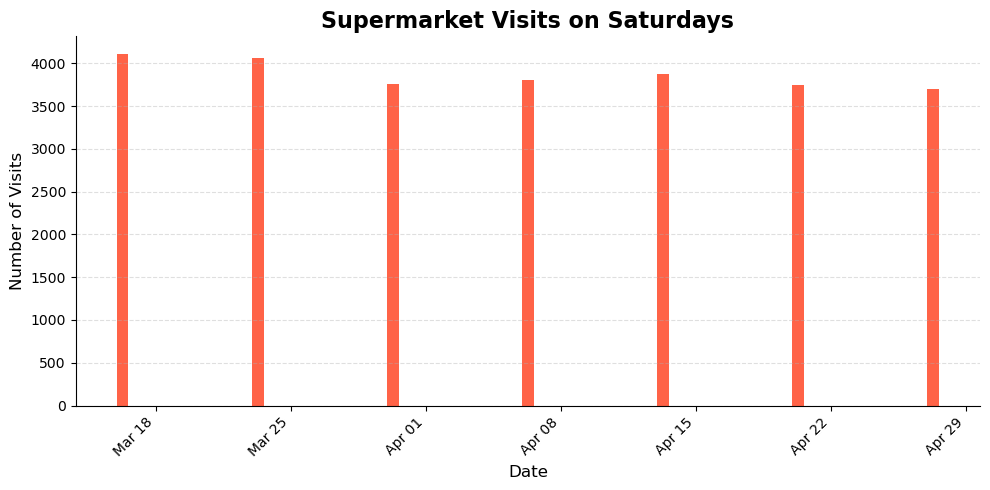

In [22]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# create day column
matched["day"] = pd.to_datetime(matched["datetime"]).dt.floor("D")

# aggregate daily visits
daily_visits = matched.groupby("day")["uid"].count().sort_index()

# filter Saturdays (Monday=0 → Saturday=5)
saturdays = daily_visits[daily_visits.index.weekday == 5]

# plot
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(saturdays.index, saturdays.values, color="tomato", width=0.6)

ax.set_title("Supermarket Visits on Saturdays", fontsize=16, weight="bold")
ax.set_ylabel("Number of Visits", fontsize=12)
ax.set_xlabel("Date", fontsize=12)

# format dates nicely
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))  # one tick per Saturday
plt.xticks(rotation=45, ha="right")

# clean style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

matched["datetime"] = pd.to_datetime(matched["datetime"])
matched["day"] = matched["datetime"].dt.floor("D")
matched["hour"] = matched["datetime"].dt.hour

storm_day = pd.Timestamp("2024-03-30")
counties = ["Los Angeles", "Ventura", "Santa Barbara"]

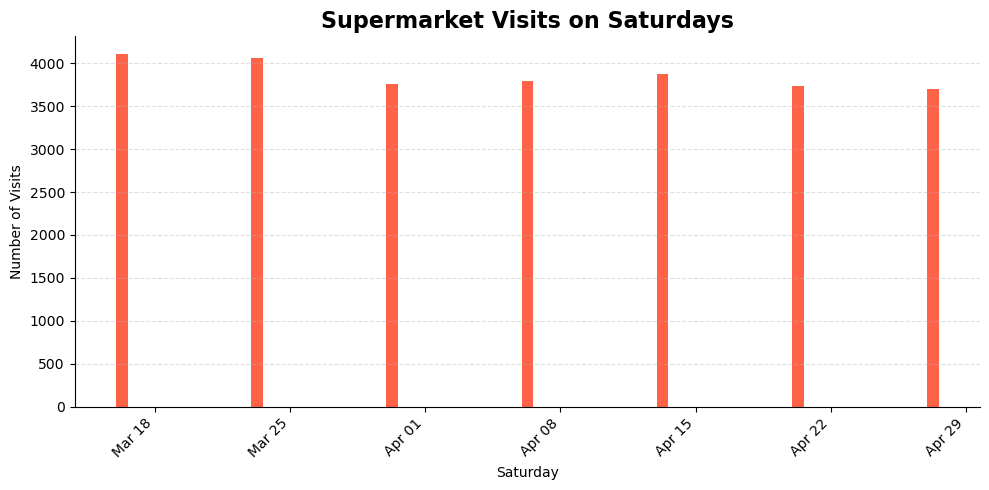

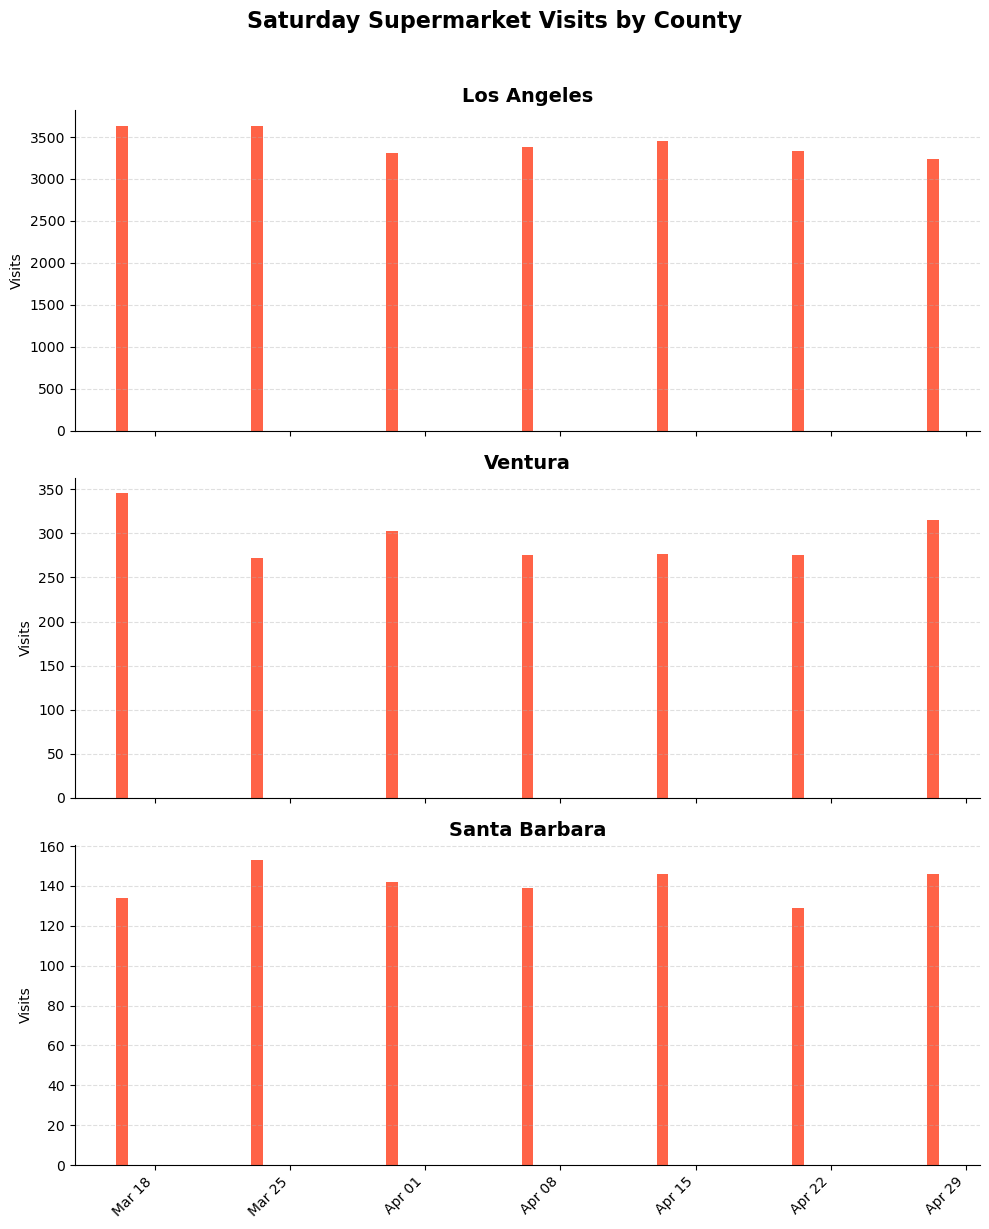

In [24]:
def plot_saturday_daily(df, title):
    daily_visits = df.groupby("day")["uid"].count().sort_index()
    saturdays = daily_visits[daily_visits.index.weekday == 5]

    colors = ["darkred" if d == storm_day else "tomato" for d in saturdays.index]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(saturdays.index, saturdays.values, color=colors, width=0.6)

    ax.set_title(title, fontsize=16, weight="bold")
    ax.set_ylabel("Number of Visits")
    ax.set_xlabel("Saturday")

    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
    plt.xticks(rotation=45, ha="right")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

# overall
plot_saturday_daily(matched, "Supermarket Visits on Saturdays")

# by county
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

for ax, county in zip(axes, counties):
    dfc = matched[matched["county"] == county]
    daily_visits = dfc.groupby("day")["uid"].count().sort_index()
    saturdays = daily_visits[daily_visits.index.weekday == 5]
    colors = ["darkred" if d == storm_day else "tomato" for d in saturdays.index]

    ax.bar(saturdays.index, saturdays.values, color=colors, width=0.6)
    ax.set_title(county, fontsize=14, weight="bold")
    ax.set_ylabel("Visits")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=7))
plt.xticks(rotation=45, ha="right")
fig.suptitle("Saturday Supermarket Visits by County", fontsize=16, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# make sure datetime is proper pandas datetime
matched["datetime"] = pd.to_datetime(matched["datetime"], errors="coerce")

# remove timezone if present
if getattr(matched["datetime"].dt, "tz", None) is not None:
    matched["datetime"] = matched["datetime"].dt.tz_localize(None)

# create clean day + hour columns
matched["day"] = matched["datetime"].dt.floor("D")
matched["hour"] = matched["datetime"].dt.hour

storm_day = pd.Timestamp("2024-03-30")
ar_days = pd.to_datetime(["2024-03-29", "2024-03-30", "2024-03-31", "2024-04-01"])
counties = ["Los Angeles", "Ventura", "Santa Barbara"]

print(matched[["datetime", "day", "hour"]].head())
print("Datetime tz:", getattr(matched["datetime"].dt, "tz", None))

             datetime        day  hour
0 2024-03-23 10:30:33 2024-03-23    10
1 2024-03-24 13:08:36 2024-03-24    13
2 2024-04-26 11:46:00 2024-04-26    11
3 2024-04-28 15:34:44 2024-04-28    15
4 2024-03-28 19:27:01 2024-03-28    19
Datetime tz: None


In [28]:
def saturday_baseline_vs_storm(df, storm_day):
    df = df.copy()
    df["day"] = pd.to_datetime(df["day"]).dt.floor("D")

    daily_visits = df.groupby("day")["uid"].count().sort_index()
    saturdays = daily_visits[daily_visits.index.weekday == 5]

    baseline = saturdays[saturdays.index != storm_day]

    if storm_day not in saturdays.index:
        raise ValueError(f"{storm_day.date()} is not present in the Saturday series.")

    storm_val = saturdays.loc[storm_day]

    out = pd.DataFrame({
        "group": ["Baseline Saturdays", "Storm Saturday"],
        "visits": [baseline.mean(), storm_val]
    })

    return out, baseline, storm_val

In [29]:
comp_all, baseline_all, storm_all = saturday_baseline_vs_storm(matched, storm_day)
print(comp_all)

                group  visits
0  Baseline Saturdays  3880.5
1      Storm Saturday  3757.0


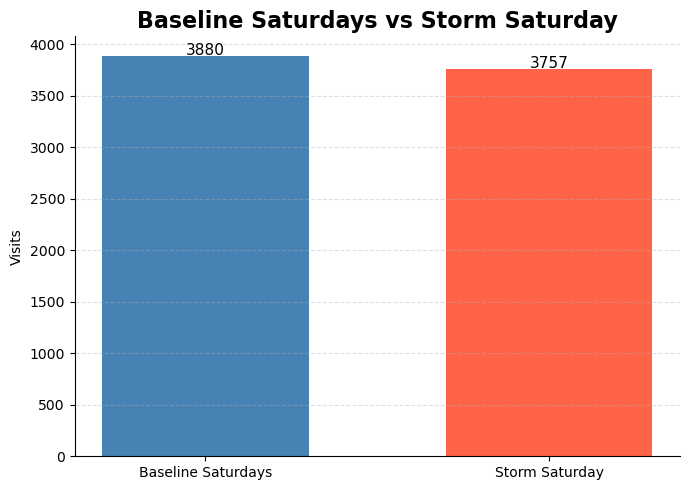

In [30]:
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    comp_all["group"],
    comp_all["visits"],
    color=["steelblue", "tomato"],
    width=0.6
)

ax.set_title("Baseline Saturdays vs Storm Saturday", fontsize=16, weight="bold")
ax.set_ylabel("Visits")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for i, v in enumerate(comp_all["visits"]):
    ax.text(i, v + 10, f"{v:.0f}", ha="center", fontsize=11)

plt.tight_layout()
plt.show()

In [31]:
def hourly_baseline_vs_storm(df, storm_day):
    df = df.copy()
    df["day"] = pd.to_datetime(df["day"]).dt.floor("D")
    df["hour"] = pd.to_datetime(df["datetime"]).dt.hour

    saturday_df = df[df["day"].dt.weekday == 5].copy()

    baseline_df = saturday_df[saturday_df["day"] != storm_day]
    storm_df = saturday_df[saturday_df["day"] == storm_day]

    baseline_hourly = baseline_df.groupby("hour")["uid"].count()
    storm_hourly = storm_df.groupby("hour")["uid"].count()

    baseline_n_days = baseline_df["day"].nunique()
    if baseline_n_days > 0:
        baseline_hourly = baseline_hourly / baseline_n_days

    hourly = pd.DataFrame({
        "Baseline Saturdays": baseline_hourly,
        "Storm Saturday": storm_hourly
    }).fillna(0)

    hourly = hourly.reindex(range(24), fill_value=0)

    return hourly

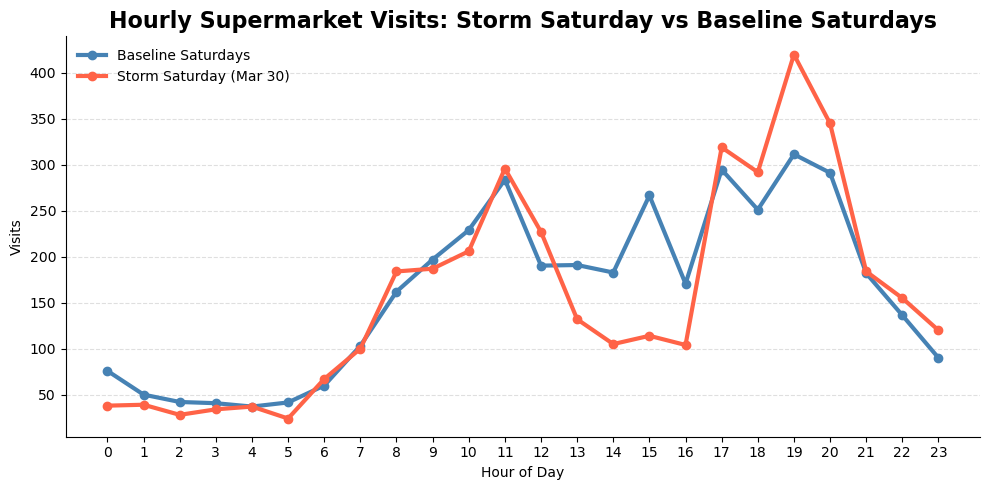

In [32]:
hourly_all = hourly_baseline_vs_storm(matched, storm_day)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    hourly_all.index,
    hourly_all["Baseline Saturdays"],
    linewidth=3,
    marker="o",
    label="Baseline Saturdays",
    color="steelblue"
)

ax.plot(
    hourly_all.index,
    hourly_all["Storm Saturday"],
    linewidth=3,
    marker="o",
    label="Storm Saturday (Mar 30)",
    color="tomato"
)

ax.set_title("Hourly Supermarket Visits: Storm Saturday vs Baseline Saturdays", fontsize=16, weight="bold")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Visits")
ax.set_xticks(range(24))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

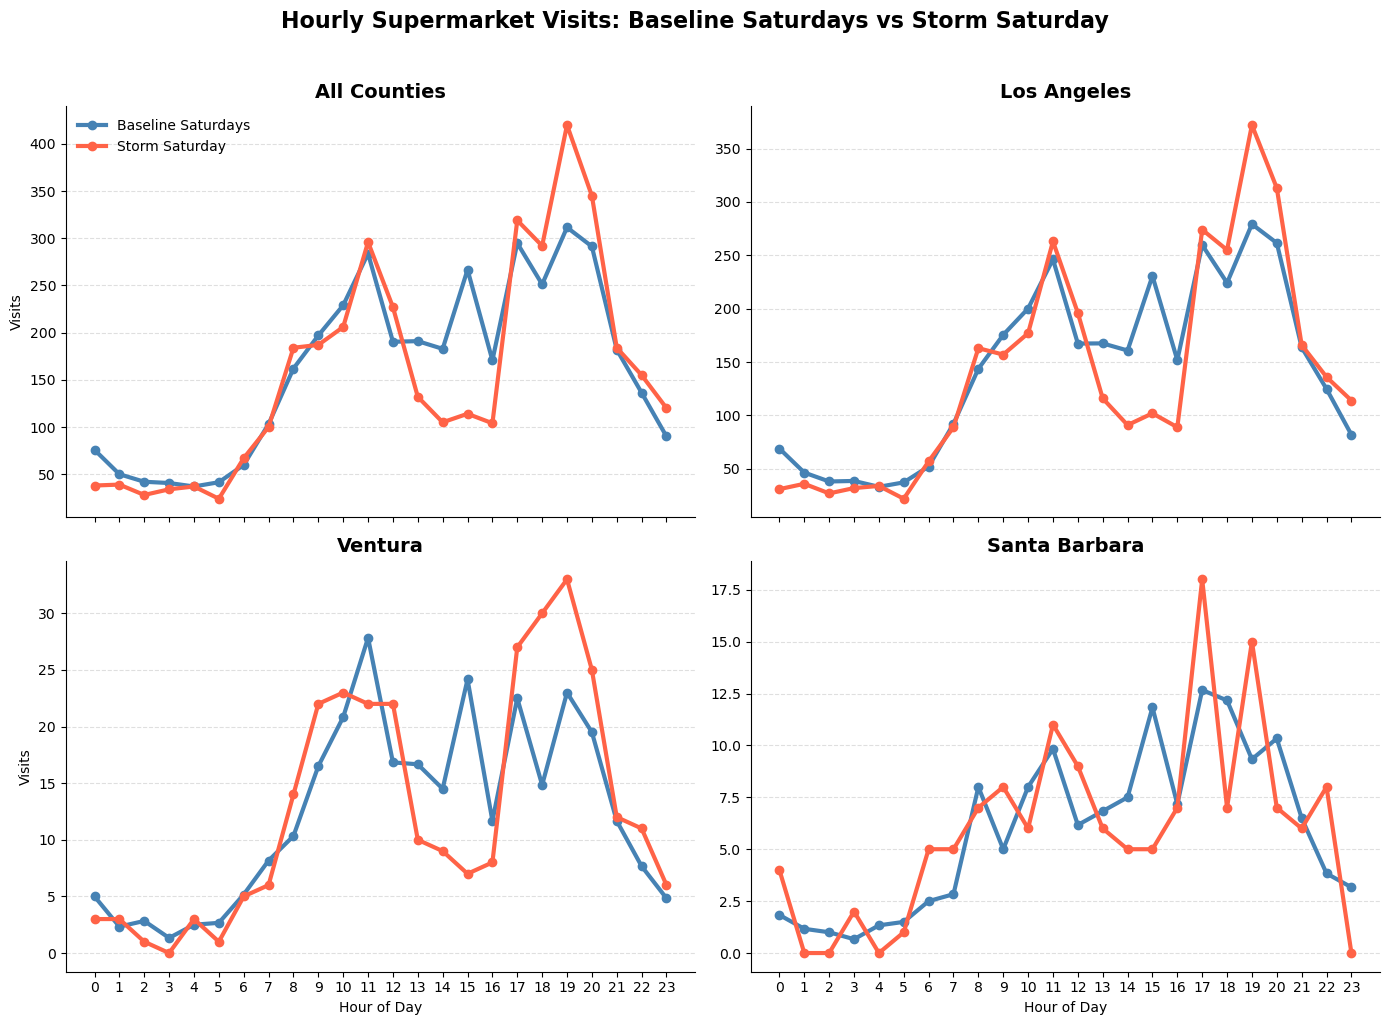

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=False)
axes = axes.flatten()

panel_defs = [("All Counties", matched)] + [(c, matched[matched["county"] == c]) for c in counties]

for ax, (label, dfsub) in zip(axes, panel_defs):
    hourly = hourly_baseline_vs_storm(dfsub, storm_day)

    ax.plot(
        hourly.index,
        hourly["Baseline Saturdays"],
        linewidth=3,
        marker="o",
        label="Baseline Saturdays",
        color="steelblue"
    )

    ax.plot(
        hourly.index,
        hourly["Storm Saturday"],
        linewidth=3,
        marker="o",
        label="Storm Saturday",
        color="tomato"
    )

    ax.set_title(label, fontsize=14, weight="bold")
    ax.set_xticks(range(24))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].legend(frameon=False)
for ax in axes[2:]:
    ax.set_xlabel("Hour of Day")
for ax in [axes[0], axes[2]]:
    ax.set_ylabel("Visits")

fig.suptitle("Hourly Supermarket Visits: Baseline Saturdays vs Storm Saturday", fontsize=16, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

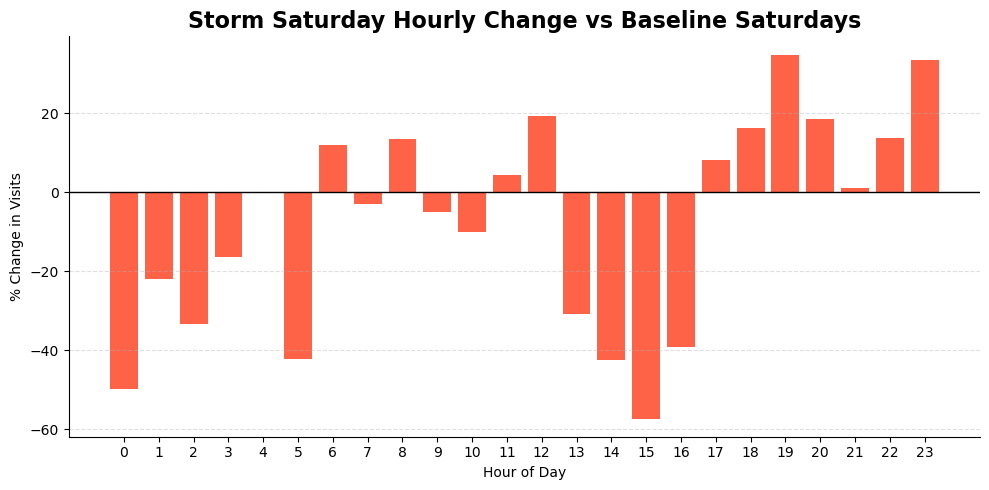

In [34]:
hourly_all = hourly_baseline_vs_storm(matched, storm_day).copy()

hourly_all["Pct Change"] = (
    (hourly_all["Storm Saturday"] - hourly_all["Baseline Saturdays"])
    / hourly_all["Baseline Saturdays"].replace(0, pd.NA)
) * 100

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(hourly_all.index, hourly_all["Pct Change"], color="tomato", width=0.8)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("Storm Saturday Hourly Change vs Baseline Saturdays", fontsize=16, weight="bold")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("% Change in Visits")
ax.set_xticks(range(24))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [35]:
def dwell_baseline_vs_storm(df, storm_day):
    df = df.copy()
    df["day"] = pd.to_datetime(df["day"]).dt.floor("D")

    saturday_df = df[df["day"].dt.weekday == 5]

    baseline_df = saturday_df[saturday_df["day"] != storm_day]
    storm_df = saturday_df[saturday_df["day"] == storm_day]

    baseline_mean = baseline_df["duration_min"].mean()
    storm_mean = storm_df["duration_min"].mean()

    out = pd.DataFrame({
        "group": ["Baseline Saturdays", "Storm Saturday"],
        "dwell_min": [baseline_mean, storm_mean]
    })

    return out

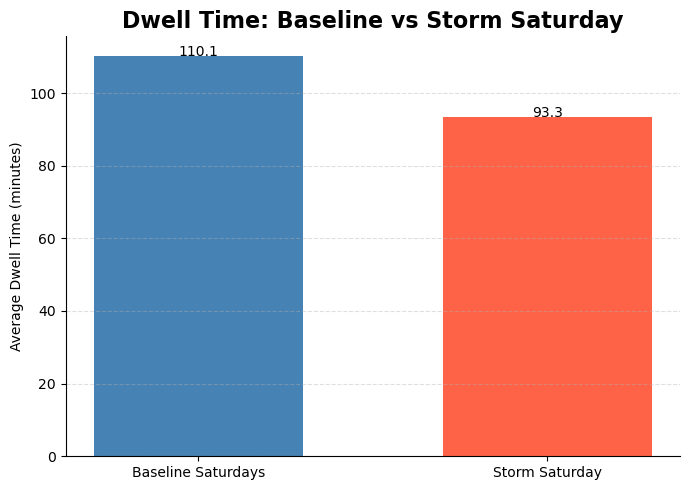

In [36]:
comp_dwell = dwell_baseline_vs_storm(matched, storm_day)

fig, ax = plt.subplots(figsize=(7,5))

ax.bar(comp_dwell["group"], comp_dwell["dwell_min"],
       color=["steelblue", "tomato"], width=0.6)

ax.set_title("Dwell Time: Baseline vs Storm Saturday", fontsize=16, weight="bold")
ax.set_ylabel("Average Dwell Time (minutes)")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for i, v in enumerate(comp_dwell["dwell_min"]):
    ax.text(i, v + 0.2, f"{v:.1f}", ha="center")

plt.tight_layout()
plt.show()

In [37]:
def hourly_dwell_baseline_vs_storm(df, storm_day):
    df = df.copy()
    df["day"] = pd.to_datetime(df["day"]).dt.floor("D")
    df["hour"] = df["datetime"].dt.hour

    saturday_df = df[df["day"].dt.weekday == 5]

    baseline_df = saturday_df[saturday_df["day"] != storm_day]
    storm_df = saturday_df[saturday_df["day"] == storm_day]

    baseline_hourly = baseline_df.groupby("hour")["duration_min"].mean()
    storm_hourly = storm_df.groupby("hour")["duration_min"].mean()

    hourly = pd.DataFrame({
        "Baseline Saturdays": baseline_hourly,
        "Storm Saturday": storm_hourly
    }).fillna(0)

    return hourly.reindex(range(24), fill_value=0)

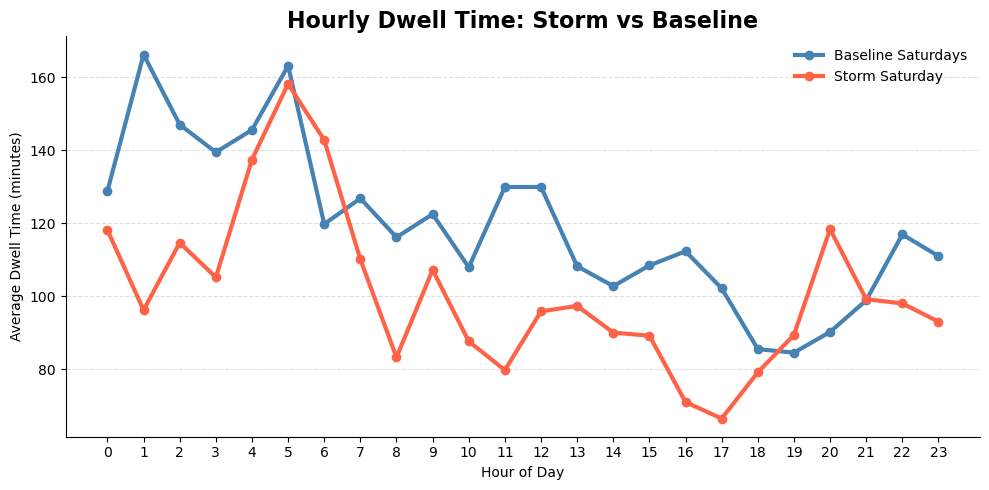

In [38]:
hourly_dwell = hourly_dwell_baseline_vs_storm(matched, storm_day)

fig, ax = plt.subplots(figsize=(10,5))

ax.plot(hourly_dwell.index, hourly_dwell["Baseline Saturdays"],
        linewidth=3, marker="o", color="steelblue", label="Baseline Saturdays")

ax.plot(hourly_dwell.index, hourly_dwell["Storm Saturday"],
        linewidth=3, marker="o", color="tomato", label="Storm Saturday")

ax.set_title("Hourly Dwell Time: Storm vs Baseline", fontsize=16, weight="bold")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Dwell Time (minutes)")
ax.set_xticks(range(24))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

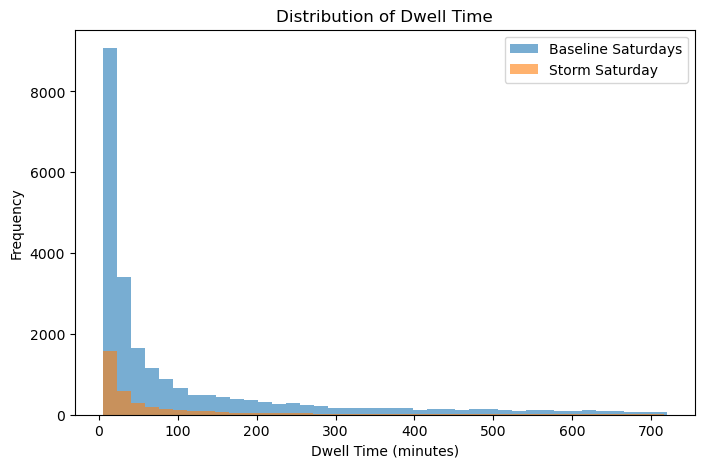

In [39]:
baseline = matched[(matched["day"].dt.weekday == 5) & (matched["day"] != storm_day)]
storm = matched[matched["day"] == storm_day]

plt.figure(figsize=(8,5))

plt.hist(baseline["duration_min"], bins=40, alpha=0.6, label="Baseline Saturdays")
plt.hist(storm["duration_min"], bins=40, alpha=0.6, label="Storm Saturday")

plt.xlabel("Dwell Time (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of Dwell Time")
plt.legend()

plt.show()

In [40]:
def hourly_difference(df, storm_day):
    hourly = hourly_baseline_vs_storm(df, storm_day).copy()

    hourly["Difference"] = (
        hourly["Storm Saturday"] - hourly["Baseline Saturdays"]
    )

    return hourly

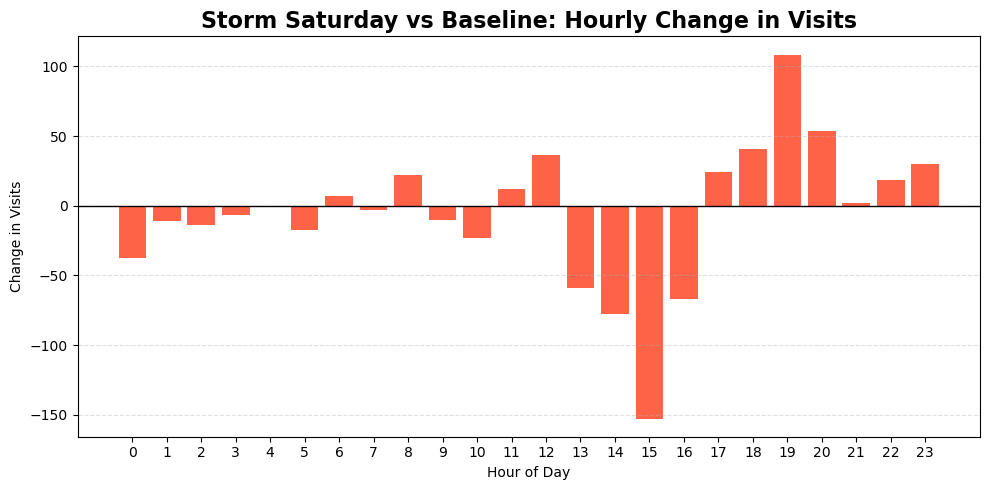

In [41]:
hourly_diff = hourly_difference(matched, storm_day)

plt.figure(figsize=(10,5))

plt.bar(hourly_diff.index, hourly_diff["Difference"], color="tomato")

plt.axhline(0, color="black", linewidth=1)

plt.title("Storm Saturday vs Baseline: Hourly Change in Visits", fontsize=16, weight="bold")
plt.xlabel("Hour of Day")
plt.ylabel("Change in Visits")
plt.xticks(range(24))

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

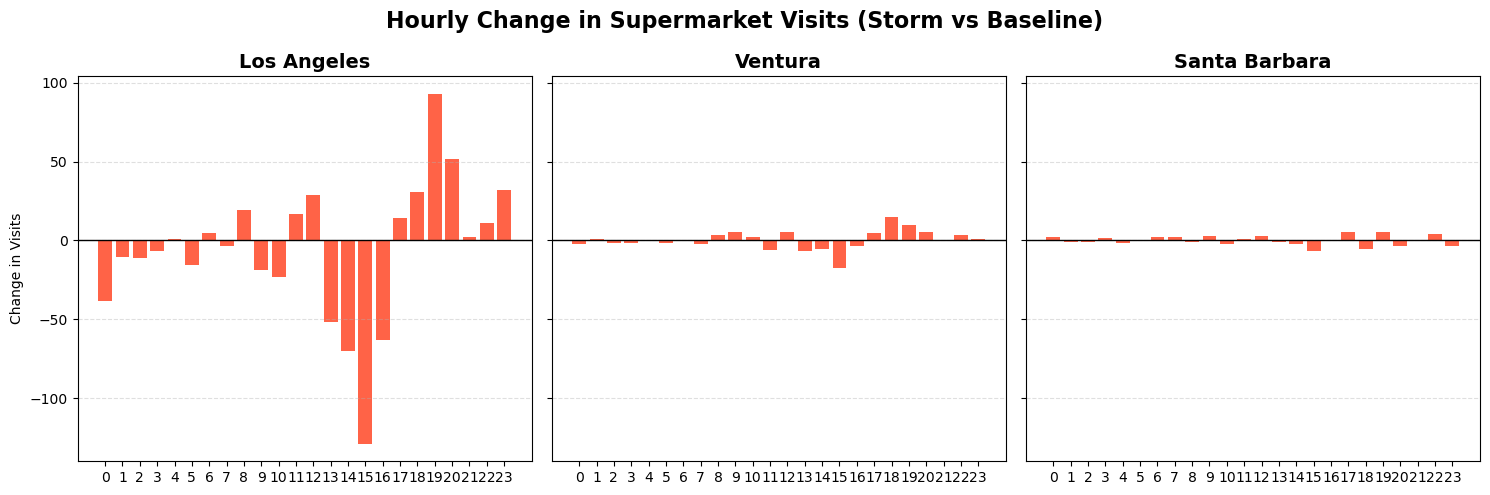

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15,5), sharey=True)

for ax, county in zip(axes, counties):
    dfc = matched[matched["county"] == county]
    hourly_diff = hourly_difference(dfc, storm_day)

    ax.bar(hourly_diff.index, hourly_diff["Difference"], color="tomato")
    ax.axhline(0, color="black", linewidth=1)

    ax.set_title(county, fontsize=14, weight="bold")
    ax.set_xticks(range(0,24))
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].set_ylabel("Change in Visits")

plt.suptitle("Hourly Change in Supermarket Visits (Storm vs Baseline)", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

In [44]:
storm_day = pd.Timestamp("2024-03-29")

df_sb = matched[matched["county"] == "Santa Barbara"].copy()
df_sb["day"] = pd.to_datetime(df_sb["day"]).dt.floor("D")
df_sb["hour"] = df_sb["datetime"].dt.hour

# Fridays only
fridays = df_sb[df_sb["day"].dt.weekday == 4]

baseline = fridays[fridays["day"] != storm_day]
storm = fridays[fridays["day"] == storm_day]

# hourly
baseline_hourly = baseline.groupby("hour")["uid"].count() / baseline["day"].nunique()
storm_hourly = storm.groupby("hour")["uid"].count()

hourly = pd.DataFrame({
    "Baseline Fridays": baseline_hourly,
    "Storm Friday (Mar 29)": storm_hourly
}).fillna(0).reindex(range(24), fill_value=0)

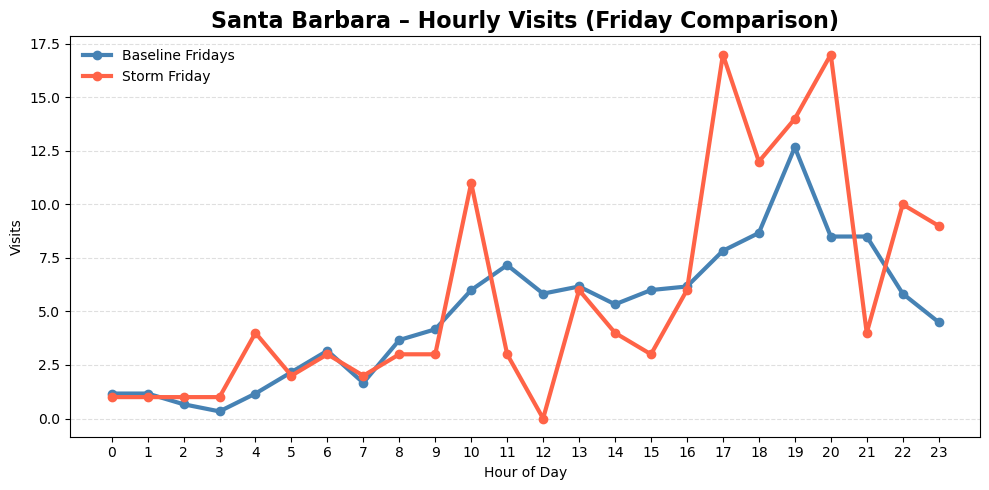

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(hourly.index, hourly["Baseline Fridays"],
         color="steelblue", linewidth=3, marker="o", label="Baseline Fridays")

plt.plot(hourly.index, hourly["Storm Friday (Mar 29)"],
         color="tomato", linewidth=3, marker="o", label="Storm Friday")

plt.title("Santa Barbara – Hourly Visits (Friday Comparison)", fontsize=16, weight="bold")
plt.xlabel("Hour of Day")
plt.ylabel("Visits")
plt.xticks(range(24))

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(frameon=False)

plt.tight_layout()
plt.show()

In [46]:
storm_day = pd.Timestamp("2024-03-29")

df_sb = matched[matched["county"] == "Santa Barbara"].copy()
df_sb["day"] = pd.to_datetime(df_sb["day"]).dt.floor("D")
df_sb["hour"] = df_sb["datetime"].dt.hour

# Fridays only
fridays = df_sb[df_sb["day"].dt.weekday == 4]

baseline = fridays[fridays["day"] != storm_day]
storm = fridays[fridays["day"] == storm_day]

# hourly dwell (mean)
baseline_hourly = baseline.groupby("hour")["duration_min"].mean()
storm_hourly = storm.groupby("hour")["duration_min"].mean()

hourly = pd.DataFrame({
    "Baseline Fridays": baseline_hourly,
    "Storm Friday (Mar 29)": storm_hourly
}).fillna(0).reindex(range(24), fill_value=0)

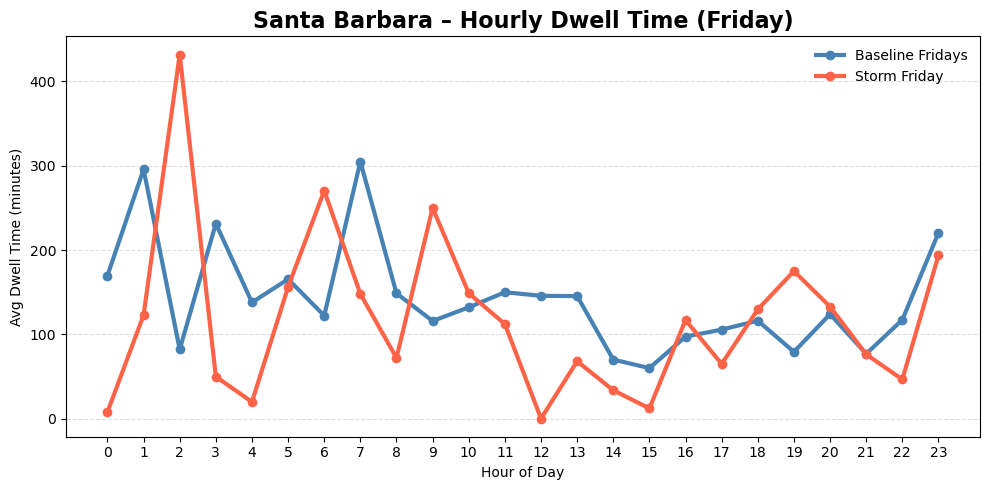

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(hourly.index, hourly["Baseline Fridays"],
         color="steelblue", linewidth=3, marker="o", label="Baseline Fridays")

plt.plot(hourly.index, hourly["Storm Friday (Mar 29)"],
         color="tomato", linewidth=3, marker="o", label="Storm Friday")

plt.title("Santa Barbara – Hourly Dwell Time (Friday)", fontsize=16, weight="bold")
plt.xlabel("Hour of Day")
plt.ylabel("Avg Dwell Time (minutes)")
plt.xticks(range(24))

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(frameon=False)

plt.tight_layout()
plt.show()

In [48]:
df_sb = matched[matched["county"] == "Santa Barbara"]

print("Unique POIs:", df_sb["poi_id"].nunique())
print("Total visits:", len(df_sb))
print("Unique devices:", df_sb["uid"].nunique())

Unique POIs: 42
Total visits: 6528
Unique devices: 3804


In [50]:
storm_day = pd.Timestamp("2024-03-29")

storm = df_sb[df_sb["day"] == storm_day]
baseline = df_sb[df_sb["day"] != storm_day]

storm_counts = storm.groupby(["poi_id","poi_lat","poi_lon"]).size().reset_index(name="storm_visits")
base_counts = baseline.groupby(["poi_id","poi_lat","poi_lon"]).size().reset_index(name="baseline_visits")

merged = storm_counts.merge(base_counts, on=["poi_id","poi_lat","poi_lon"], how="outer").fillna(0)

merged["diff"] = merged["storm_visits"] - merged["baseline_visits"]

In [51]:
m = folium.Map(
    location=[merged["poi_lat"].mean(), merged["poi_lon"].mean()],
    zoom_start=10
)

for _, row in merged.iterrows():
    color = "red" if row["diff"] > 0 else "blue"

    folium.CircleMarker(
        location=[row["poi_lat"], row["poi_lon"]],
        radius=4 + abs(row["diff"]),
        color=color,
        fill=True,
        fill_opacity=0.7,
        popup=f"Δ visits: {row['diff']}"
    ).add_to(m)

m

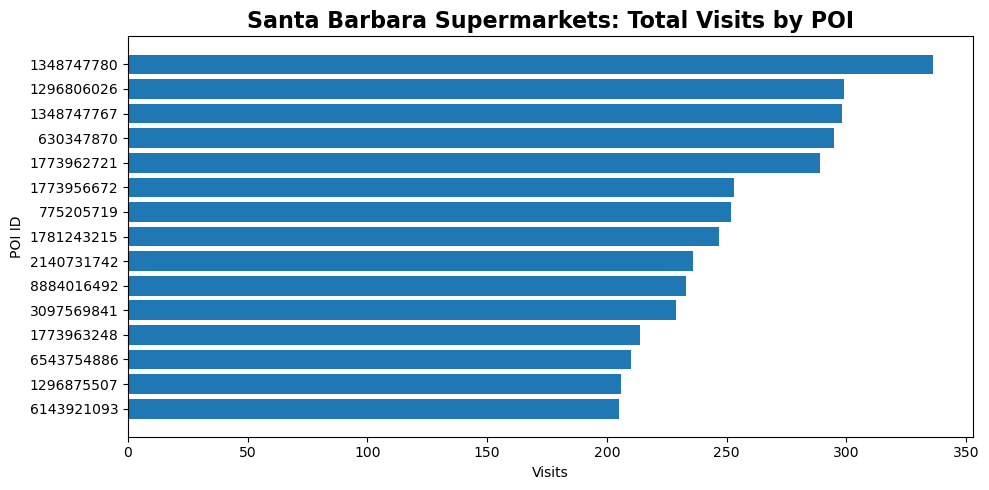

In [54]:
poi_counts = (
    df_sb.groupby("poi_id")
    .size()
    .sort_values(ascending=False)
    .reset_index(name="visits")
    .head(15)
)

plt.figure(figsize=(10,5))
plt.barh(poi_counts["poi_id"].astype(str), poi_counts["visits"])
plt.gca().invert_yaxis()
plt.title("Santa Barbara Supermarkets: Total Visits by POI", fontsize=16, weight="bold")
plt.xlabel("Visits")
plt.ylabel("POI ID")
plt.tight_layout()
plt.show()

# Grouping by POI Brand

In [56]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

poi_path = "/glade/campaign/cisl/aiml/cat_flood/ancillary_data/POIs/California_filtered_pois.geojson"

# read POI lookup
pois = gpd.read_file(poi_path)

# keep only the fields needed and rename id -> poi_id
poi_lookup = (
    pois[["id", "name", "type", "lat", "lon"]]
    .rename(columns={"id": "poi_id", "type": "poi_type_lookup"})
    .drop_duplicates(subset=["poi_id"])
)

# make sure join key types match
matched["poi_id"] = matched["poi_id"].astype(str)
poi_lookup["poi_id"] = poi_lookup["poi_id"].astype(str)

# merge names into matched visits
matched_named = matched.merge(poi_lookup, on="poi_id", how="left")

# quick check
print(matched_named[["poi_id", "name", "county"]].head())
print("Matched names:", matched_named["name"].notna().sum(), "of", len(matched_named))

        poi_id                    name       county
0   8994258716  Sprouts Farmers Market  Los Angeles
1  11663856411    Stater Bros. Markets  Los Angeles
2   1932402430          Boba Tea House  Los Angeles
3  11989079604           Smart & Final  Los Angeles
4   1897562819                  Ralphs  Los Angeles
Matched names: 172205 of 172205


In [57]:
 df_sb = matched_named[matched_named["county"] == "Santa Barbara"].copy()

poi_counts = (
    df_sb.groupby(["poi_id", "name"], dropna=False)
    .size()
    .reset_index(name="visits")
    .sort_values("visits", ascending=False)
    .head(15)
)

poi_counts["label"] = poi_counts["name"].fillna("Unknown POI")

print(poi_counts)

        poi_id                         name  visits  \
7   1348747780                 Trader Joe's     336   
4   1296806026                   Albertsons     299   
6   1348747767                   Albertsons     298   
28   630347870                 Trader Joe's     295   
11  1773962721                     FoodMaxx     289   
10  1773956672                     Foods Co     253   
36   775205719                   Albertsons     252   
13  1781243215                     Vallarta     247   
16  2140731742  Walmart Neighborhood Market     236   
41  8884016492       Tino's Italian Grocery     233   
19  3097569841               Village Market     229   
12  1773963248                     FoodMaxx     214   
31  6543754886       Sprouts Farmers Market     210   
5   1296875507      Spencer's Fresh Markets     206   
27  6143921093               Grocery Outlet     205   

                          label  
7                  Trader Joe's  
4                    Albertsons  
6                

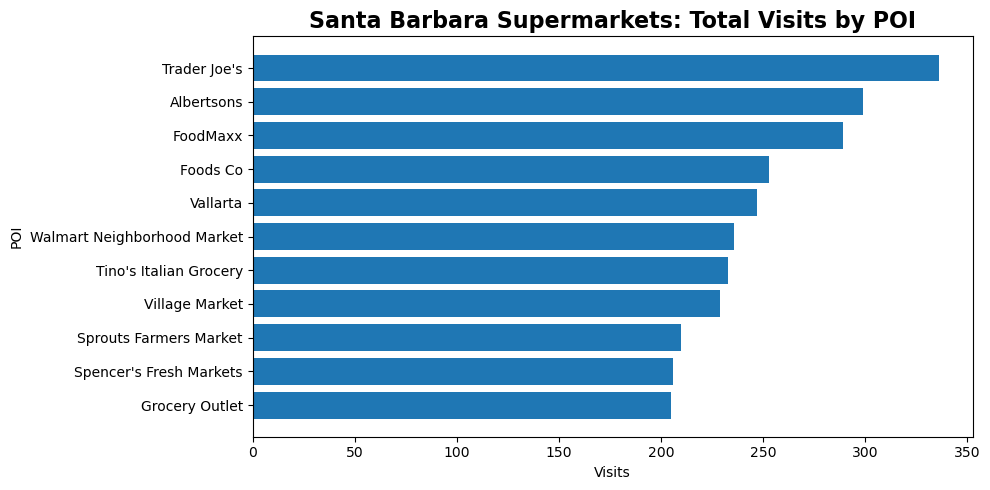

In [58]:
plt.figure(figsize=(10,5))
plt.barh(poi_counts["label"], poi_counts["visits"])
plt.gca().invert_yaxis()
plt.title("Santa Barbara Supermarkets: Total Visits by POI", fontsize=16, weight="bold")
plt.xlabel("Visits")
plt.ylabel("POI")
plt.tight_layout()
plt.show()

In [59]:
storm_day = pd.Timestamp("2024-03-29")

df_sb["day"] = pd.to_datetime(df_sb["day"]).dt.floor("D")
fridays = df_sb[df_sb["day"].dt.weekday == 4]

storm = fridays[fridays["day"] == storm_day]
baseline = fridays[fridays["day"] != storm_day]

storm_counts = storm.groupby(["poi_id", "name"]).size().rename("storm_visits")
baseline_counts = baseline.groupby(["poi_id", "name"]).size().rename("baseline_total")

n_baseline_days = baseline["day"].nunique()

poi_compare = pd.concat([storm_counts, baseline_counts], axis=1).fillna(0)
poi_compare["baseline_avg"] = poi_compare["baseline_total"] / n_baseline_days
poi_compare["diff"] = poi_compare["storm_visits"] - poi_compare["baseline_avg"]
poi_compare = poi_compare.reset_index().sort_values("diff", ascending=False)

poi_compare["label"] = poi_compare["name"].fillna("Unknown POI")
print(poi_compare.head(15))

         poi_id                         name  storm_visits  baseline_total  \
9    1773963248                     FoodMaxx          11.0            19.0   
18    467874261                         Vons           7.0             7.0   
16   3097569841               Village Market          12.0            38.0   
13   2140731742  Walmart Neighborhood Market           8.0            15.0   
30    671782461                 Trader Joe's           5.0             2.0   
10   1781243215                     Vallarta           8.0            25.0   
25    648508441                       Ralphs           6.0            15.0   
20   5330411056                Smart & Final           4.0             4.0   
27   6543754886       Sprouts Farmers Market           7.0            24.0   
35   8429741866                 Mesa Produce           3.0             1.0   
6    1656456682                     Gelson's           5.0            14.0   
24    630347870                 Trader Joe's           6.0      

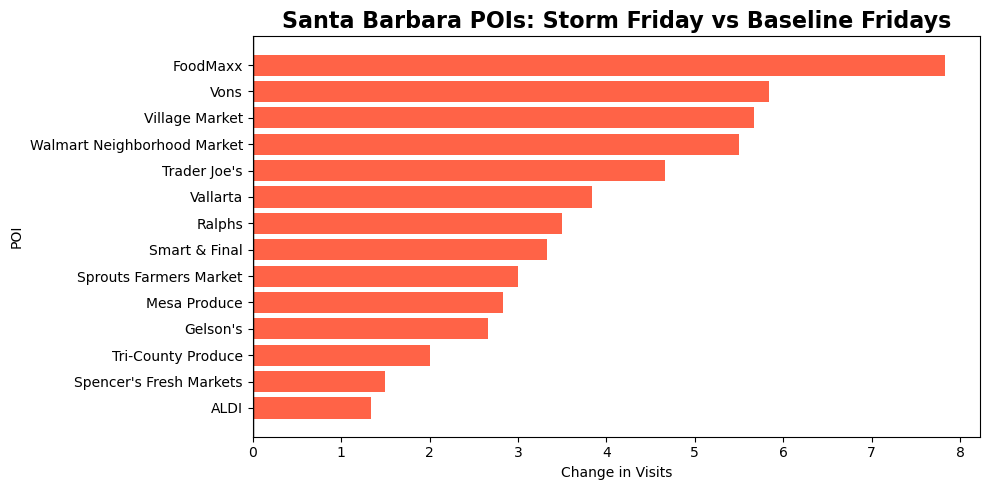

In [60]:
top_diff = poi_compare.head(15).copy()
colors = ["tomato" if x >= 0 else "steelblue" for x in top_diff["diff"]]

plt.figure(figsize=(10,5))
plt.barh(top_diff["label"], top_diff["diff"], color=colors)
plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=1)
plt.title("Santa Barbara POIs: Storm Friday vs Baseline Fridays", fontsize=16, weight="bold")
plt.xlabel("Change in Visits")
plt.ylabel("POI")
plt.tight_layout()
plt.show()

In [61]:
poi_compare["label"] = poi_compare["name"].fillna("Unknown POI")

top_inc = poi_compare.sort_values("diff", ascending=False).head(5).copy()
top_dec = poi_compare.sort_values("diff", ascending=True).head(5).copy()

print("Top 5 increases")
print(top_inc[["label", "storm_visits", "baseline_avg", "diff"]])

print("\nTop 5 decreases")
print(top_dec[["label", "storm_visits", "baseline_avg", "diff"]])

Top 5 increases
                          label  storm_visits  baseline_avg      diff
9                      FoodMaxx          11.0      3.166667  7.833333
18                         Vons           7.0      1.166667  5.833333
16               Village Market          12.0      6.333333  5.666667
13  Walmart Neighborhood Market           8.0      2.500000  5.500000
30                 Trader Joe's           5.0      0.333333  4.666667

Top 5 decreases
                 label  storm_visits  baseline_avg      diff
5         Trader Joe's           2.0      6.833333 -4.833333
31       Smart & Final           1.0      4.666667 -3.666667
23      Grocery Outlet           2.0      5.333333 -3.333333
33     Foodland Market           1.0      4.000000 -3.000000
11  La Princesa Market           2.0      4.666667 -2.666667


In [62]:
top_changes = pd.concat([
    top_inc.assign(change_type="Increase"),
    top_dec.assign(change_type="Decrease")
])

top_changes[["change_type", "label", "storm_visits", "baseline_avg", "diff"]]

,change_type,label,storm_visits,baseline_avg,diff
9,Increase,FoodMaxx,11.0,3.166667,7.833333
18,Increase,Vons,7.0,1.166667,5.833333
16,Increase,Village Market,12.0,6.333333,5.666667
13,Increase,Walmart Neighborhood Market,8.0,2.500000,5.500000
30,Increase,Trader Joe's,5.0,0.333333,4.666667
5,Decrease,Trader Joe's,2.0,6.833333,-4.833333
31,Decrease,Smart & Final,1.0,4.666667,-3.666667
23,Decrease,Grocery Outlet,2.0,5.333333,-3.333333
33,Decrease,Foodland Market,1.0,4.000000,-3.000000
11,Decrease,La Princesa Market,2.0,4.666667,-2.666667


In [63]:
import folium
import numpy as np

map_df = poi_compare.copy()

# simple categories
map_df["change_cat"] = np.where(
    map_df["diff"] > 0, "Increase",
    np.where(map_df["diff"] < 0, "Decrease", "No change")
)

# keep one row per POI with coordinates
poi_coords = (
    matched_named[matched_named["county"] == "Santa Barbara"][["poi_id", "name", "poi_lat", "poi_lon"]]
    .drop_duplicates(subset=["poi_id"])
)

map_df = map_df.merge(poi_coords, on=["poi_id", "name"], how="left")

m = folium.Map(
    location=[map_df["poi_lat"].mean(), map_df["poi_lon"].mean()],
    zoom_start=10,
    tiles="cartodbpositron"
)

for _, row in map_df.iterrows():
    if row["change_cat"] == "Increase":
        color = "green"
    elif row["change_cat"] == "Decrease":
        color = "red"
    else:
        color = "gray"

    folium.CircleMarker(
        location=[row["poi_lat"], row["poi_lon"]],
        radius=7,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.8,
        popup=f"{row['label']}<br>Δ visits: {row['diff']:.1f}"
    ).add_to(m)

m

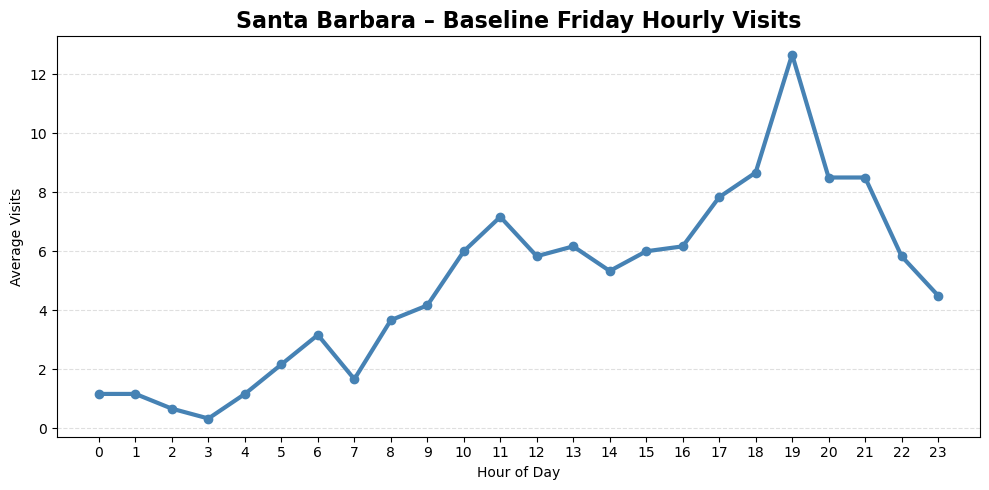

In [64]:
df_sb = matched_named[matched_named["county"] == "Santa Barbara"].copy()
df_sb["day"] = pd.to_datetime(df_sb["day"]).dt.floor("D")
df_sb["hour"] = pd.to_datetime(df_sb["datetime"]).dt.hour

fridays = df_sb[df_sb["day"].dt.weekday == 4]
baseline = fridays[fridays["day"] != pd.Timestamp("2024-03-29")]

baseline_hourly = (
    baseline.groupby("hour")["uid"].count() / baseline["day"].nunique()
).reindex(range(24), fill_value=0)

plt.figure(figsize=(10,5))
plt.plot(baseline_hourly.index, baseline_hourly.values,
         color="steelblue", linewidth=3, marker="o")

plt.title("Santa Barbara – Baseline Friday Hourly Visits", fontsize=16, weight="bold")
plt.xlabel("Hour of Day")
plt.ylabel("Average Visits")
plt.xticks(range(24))
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

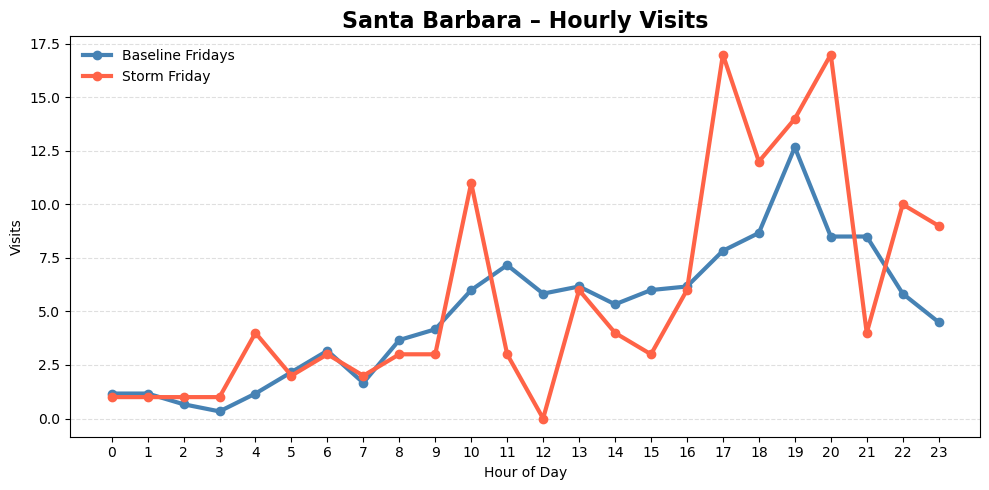

In [65]:
storm = fridays[fridays["day"] == pd.Timestamp("2024-03-29")]
storm_hourly = storm.groupby("hour")["uid"].count().reindex(range(24), fill_value=0)

plt.figure(figsize=(10,5))
plt.plot(baseline_hourly.index, baseline_hourly.values,
         color="steelblue", linewidth=3, marker="o", label="Baseline Fridays")
plt.plot(storm_hourly.index, storm_hourly.values,
         color="tomato", linewidth=3, marker="o", label="Storm Friday")

plt.title("Santa Barbara – Hourly Visits", fontsize=16, weight="bold")
plt.xlabel("Hour of Day")
plt.ylabel("Visits")
plt.xticks(range(24))
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

In [66]:
df_sb = matched_named[matched_named["county"] == "Santa Barbara"].copy()

df_sb["day"] = pd.to_datetime(df_sb["day"]).dt.floor("D")
df_sb["hour"] = pd.to_datetime(df_sb["datetime"]).dt.hour

storm_day = pd.Timestamp("2024-03-29")

# normalize names
df_sb["name_clean"] = df_sb["name"].str.lower()

def classify_brand(name):
    if pd.isna(name):
        return None
    if "trader joe" in name:
        return "Trader Joe's"
    if "neighborhood walmart" in name:
        return "Neighborhood Walmart"
    if "walmart" in name:
        return "Walmart"
    return None

df_sb["brand"] = df_sb["name_clean"].apply(classify_brand)

df_brands = df_sb[df_sb["brand"].notna()].copy()

print(df_brands["brand"].value_counts())

brand
Trader Joe's    801
Walmart         236
Name: count, dtype: int64


In [67]:
def hourly_brand(df, brand):
    d = df[df["brand"] == brand]

    fridays = d[d["day"].dt.weekday == 4]

    baseline = fridays[fridays["day"] != storm_day]
    storm = fridays[fridays["day"] == storm_day]

    baseline_hourly = baseline.groupby("hour")["uid"].count() / baseline["day"].nunique()
    storm_hourly = storm.groupby("hour")["uid"].count()

    out = pd.DataFrame({
        "Baseline": baseline_hourly,
        "Storm": storm_hourly
    }).fillna(0)

    return out.reindex(range(24), fill_value=0)

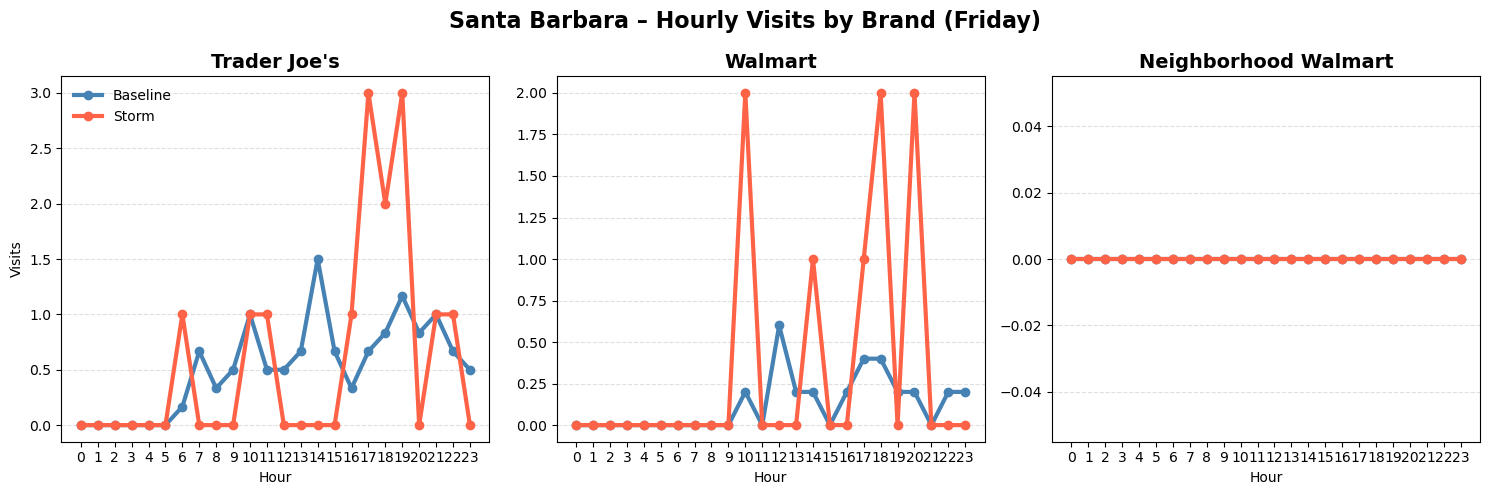

In [68]:
brands = ["Trader Joe's", "Walmart", "Neighborhood Walmart"]

fig, axes = plt.subplots(1, 3, figsize=(15,5), sharey=False)

for ax, b in zip(axes, brands):
    hourly = hourly_brand(df_brands, b)

    ax.plot(hourly.index, hourly["Baseline"],
            color="steelblue", linewidth=3, marker="o", label="Baseline")

    ax.plot(hourly.index, hourly["Storm"],
            color="tomato", linewidth=3, marker="o", label="Storm")

    ax.set_title(b, fontsize=14, weight="bold")
    ax.set_xticks(range(24))
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].set_ylabel("Visits")
axes[0].legend(frameon=False)

for ax in axes:
    ax.set_xlabel("Hour")

plt.suptitle("Santa Barbara – Hourly Visits by Brand (Friday)", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

In [70]:
# you already merged name → matched_named

matched_named["name_clean"] = matched_named["name"].str.lower()

def classify_brand(name):
    if pd.isna(name):
        return None
    if "trader joe" in name:
        return "Trader Joe's"
    if "neighborhood walmart" in name:
        return "Neighborhood Walmart"
    if "walmart" in name:
        return "Walmart"
    return None

matched_named["brand"] = matched_named["name_clean"].apply(classify_brand)

In [71]:
df_sb = matched_named[matched_named["county"] == "Santa Barbara"].copy()

brand_counts = (
    df_sb.groupby("brand")["uid"]
    .count()
    .sort_values(ascending=False)
    .reset_index(name="visits")
)

print(brand_counts)

          brand  visits
0  Trader Joe's     801
1       Walmart     236


In [72]:
top_brands = (
    brand_counts.dropna()
    .query("visits > 0")
    .head(2)["brand"]
    .tolist()
)

print("Selected brands:", top_brands)

Selected brands: ["Trader Joe's", 'Walmart']


In [73]:
storm_day = pd.Timestamp("2024-03-29")

df_sb = matched_named[matched_named["county"] == "Santa Barbara"].copy()
df_sb["day"] = pd.to_datetime(df_sb["day"]).dt.floor("D")

df_storm = df_sb[df_sb["day"] == storm_day]

brand_counts = (
    df_storm.groupby("brand")["uid"]
    .count()
    .sort_values(ascending=False)
    .reset_index(name="visits")
)

print(brand_counts)

          brand  visits
0  Trader Joe's      14
1       Walmart       8


In [74]:
storm_day = pd.Timestamp("2024-03-29")

df_sb = matched_named[matched_named["county"] == "Santa Barbara"].copy()
df_sb["day"] = pd.to_datetime(df_sb["day"]).dt.floor("D")

df_storm = df_sb[df_sb["day"] == storm_day].copy()

brand_counts = (
    df_storm.groupby("brand", dropna=False)["uid"]
    .count()
    .sort_values(ascending=False)
    .reset_index(name="visits")
)

print(brand_counts)

          brand  visits
0           NaN     115
1  Trader Joe's      14
2       Walmart       8


In [75]:
poi_counts = (
    df_storm.groupby(["name", "brand"], dropna=False)["uid"]
    .count()
    .sort_values(ascending=False)
    .reset_index(name="visits")
)

print(poi_counts.head(20))

                           name         brand  visits
0                      FoodMaxx           NaN      14
1                  Trader Joe's  Trader Joe's      14
2                    Albertsons           NaN      13
3                Village Market           NaN      12
4                      Vallarta           NaN       8
5   Walmart Neighborhood Market       Walmart       8
6        Sprouts Farmers Market           NaN       7
7                          Vons           NaN       7
8                        Ralphs           NaN       6
9                 Smart & Final           NaN       5
10                     Gelson's           NaN       5
11      Spencer's Fresh Markets           NaN       5
12           Whole Foods Market           NaN       4
13               Grocery Outlet           NaN       3
14                     Foods Co           NaN       3
15                 Mesa Produce           NaN       3
16            Santa Cruz Market           NaN       2
17              La Perla Mar

In [76]:
import pandas as pd
import matplotlib.pyplot as plt

storm_day = pd.Timestamp("2024-03-29")

df_sb = matched_named[matched_named["county"] == "Santa Barbara"].copy()
df_sb["day"] = pd.to_datetime(df_sb["day"]).dt.floor("D")

# Fridays only
fridays = df_sb[df_sb["day"].dt.weekday == 4].copy()

storm = fridays[fridays["day"] == storm_day].copy()
baseline = fridays[fridays["day"] != storm_day].copy()

storm_counts = storm.groupby(["poi_id", "name", "poi_lat", "poi_lon"]).size().rename("storm_visits")
baseline_counts = baseline.groupby(["poi_id", "name", "poi_lat", "poi_lon"]).size().rename("baseline_total")

n_baseline_days = baseline["day"].nunique()

poi_compare = pd.concat([storm_counts, baseline_counts], axis=1).fillna(0)
poi_compare["baseline_avg"] = poi_compare["baseline_total"] / n_baseline_days
poi_compare["diff"] = poi_compare["storm_visits"] - poi_compare["baseline_avg"]
poi_compare = poi_compare.reset_index().sort_values("diff", ascending=False)

print(poi_compare[["name", "storm_visits", "baseline_avg", "diff"]].head(20))

                           name  storm_visits  baseline_avg      diff
9                      FoodMaxx          11.0      3.166667  7.833333
18                         Vons           7.0      1.166667  5.833333
16               Village Market          12.0      6.333333  5.666667
13  Walmart Neighborhood Market           8.0      2.500000  5.500000
30                 Trader Joe's           5.0      0.333333  4.666667
10                     Vallarta           8.0      4.166667  3.833333
25                       Ralphs           6.0      2.500000  3.500000
20                Smart & Final           4.0      0.666667  3.333333
27       Sprouts Farmers Market           7.0      4.000000  3.000000
35                 Mesa Produce           3.0      0.166667  2.833333
6                      Gelson's           5.0      2.333333  2.666667
24                 Trader Joe's           6.0      3.833333  2.166667
34           Tri-County Produce           2.0      0.000000  2.000000
3       Spencer's Fr

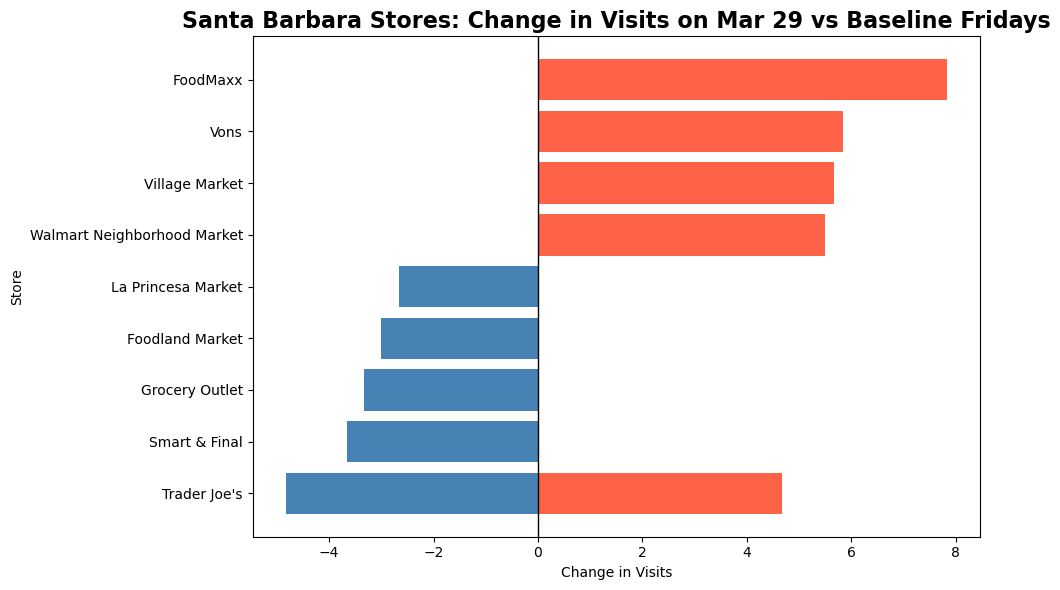

In [77]:
top_inc = poi_compare.sort_values("diff", ascending=False).head(5)
top_dec = poi_compare.sort_values("diff", ascending=True).head(5)

plot_df = pd.concat([top_inc, top_dec]).drop_duplicates(subset=["poi_id"]).copy()
plot_df = plot_df.sort_values("diff")

colors = ["steelblue" if x < 0 else "tomato" for x in plot_df["diff"]]

plt.figure(figsize=(10, 6))
plt.barh(plot_df["name"], plot_df["diff"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Santa Barbara Stores: Change in Visits on Mar 29 vs Baseline Fridays", fontsize=16, weight="bold")
plt.xlabel("Change in Visits")
plt.ylabel("Store")
plt.tight_layout()
plt.show()

In [78]:
import folium

map_df = pd.concat([top_inc, top_dec]).drop_duplicates(subset=["poi_id"]).copy()

m = folium.Map(
    location=[map_df["poi_lat"].mean(), map_df["poi_lon"].mean()],
    zoom_start=11,
    tiles="cartodbpositron"
)

for _, row in map_df.iterrows():
    color = "green" if row["diff"] > 0 else "red"

    folium.CircleMarker(
        location=[row["poi_lat"], row["poi_lon"]],
        radius=8,
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.85,
        popup=(
            f"{row['name']}<br>"
            f"Storm visits: {row['storm_visits']}<br>"
            f"Baseline avg: {row['baseline_avg']:.1f}<br>"
            f"Change: {row['diff']:.1f}"
        )
    ).add_to(m)

m

# Filter Santa Barbara Top stores changing

In [79]:
stores = ["FoodMaxx", "Vons", "Smart & Final", "Trader Joe's"]

df_sb = matched_named[matched_named["county"] == "Santa Barbara"].copy()
df_sb["day"] = pd.to_datetime(df_sb["day"]).dt.floor("D")
df_sb["hour"] = pd.to_datetime(df_sb["datetime"]).dt.hour

df_sel = df_sb[df_sb["name"].isin(stores)].copy()

storm_day = pd.Timestamp("2024-03-29")

In [80]:
def hourly_store(df, store):
    d = df[df["name"] == store]

    fridays = d[d["day"].dt.weekday == 4]

    baseline = fridays[fridays["day"] != storm_day]
    storm = fridays[fridays["day"] == storm_day]

    baseline_hourly = baseline.groupby("hour")["uid"].count() / max(baseline["day"].nunique(), 1)
    storm_hourly = storm.groupby("hour")["uid"].count()

    out = pd.DataFrame({
        "Baseline": baseline_hourly,
        "Storm": storm_hourly
    }).fillna(0)

    return out.reindex(range(24), fill_value=0)

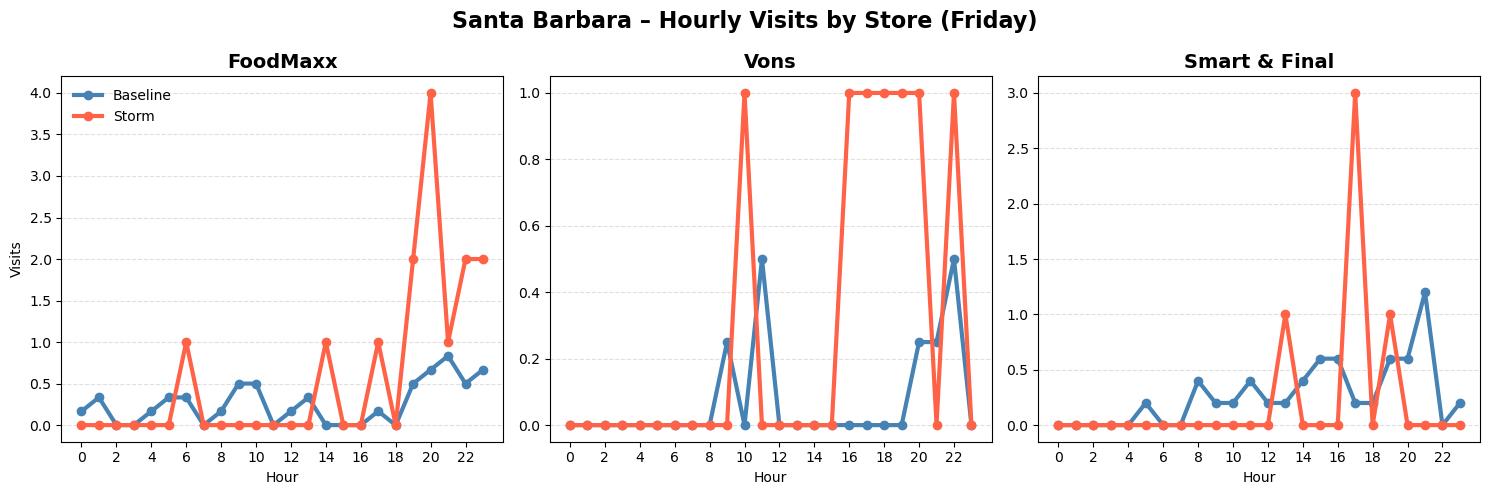

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(15,5), sharey=False)

selected = ["FoodMaxx", "Vons", "Smart & Final"]

for ax, store in zip(axes, selected):
    hourly = hourly_store(df_sel, store)

    ax.plot(hourly.index, hourly["Baseline"],
            color="steelblue", linewidth=3, marker="o", label="Baseline")

    ax.plot(hourly.index, hourly["Storm"],
            color="tomato", linewidth=3, marker="o", label="Storm")

    ax.set_title(store, fontsize=14, weight="bold")
    ax.set_xticks(range(0,24,2))
    ax.grid(axis="y", linestyle="--", alpha=0.4)

axes[0].set_ylabel("Visits")
axes[0].legend(frameon=False)

for ax in axes:
    ax.set_xlabel("Hour")

plt.suptitle("Santa Barbara – Hourly Visits by Store (Friday)", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

In [82]:
hourly["diff"] = hourly["Storm"] - hourly["Baseline"]

In [83]:
# aggregate ALL SB supermarkets
df_sb = matched_named[matched_named["county"] == "Santa Barbara"].copy()
df_sb["hour"] = pd.to_datetime(df_sb["datetime"]).dt.hour
df_sb["day"] = pd.to_datetime(df_sb["day"])

storm_day = pd.Timestamp("2024-03-29")

baseline = df_sb[(df_sb["day"].dt.weekday == 4) & (df_sb["day"] != storm_day)]
storm = df_sb[df_sb["day"] == storm_day]

baseline_hour = baseline.groupby("hour")["uid"].count() / baseline["day"].nunique()
storm_hour = storm.groupby("hour")["uid"].count()

# Figures

In [84]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium
import numpy as np

base = "/glade/work/jcelis/code/jcelis/2.mobility_code/POI_analysis/POIs_output_v5_05march2026/supermarket_baseline_rg0_All"
poi_path = "/glade/campaign/cisl/aiml/cat_flood/ancillary_data/POIs/California_filtered_pois.geojson"

matched = pd.read_parquet(f"{base}/matched_stays_with_poi_latlon.parquet")
pois = gpd.read_file(poi_path)

# keep lookup fields
poi_lookup = (
    pois[["id", "name", "type", "lat", "lon"]]
    .rename(columns={"id": "poi_id"})
    .drop_duplicates(subset=["poi_id"])
)

# make keys consistent
matched["poi_id"] = matched["poi_id"].astype(str)
poi_lookup["poi_id"] = poi_lookup["poi_id"].astype(str)

# merge names
matched_named = matched.merge(poi_lookup, on="poi_id", how="left")

# clean datetime
matched_named["datetime"] = pd.to_datetime(matched_named["datetime"], errors="coerce")
if getattr(matched_named["datetime"].dt, "tz", None) is not None:
    matched_named["datetime"] = matched_named["datetime"].dt.tz_localize(None)

matched_named["day"] = matched_named["datetime"].dt.floor("D")
matched_named["hour"] = matched_named["datetime"].dt.hour

print(matched_named[["poi_id", "name", "county", "datetime", "duration_min"]].head())

        poi_id                    name       county            datetime  \
0   8994258716  Sprouts Farmers Market  Los Angeles 2024-03-23 10:30:33   
1  11663856411    Stater Bros. Markets  Los Angeles 2024-03-24 13:08:36   
2   1932402430          Boba Tea House  Los Angeles 2024-04-26 11:46:00   
3  11989079604           Smart & Final  Los Angeles 2024-04-28 15:34:44   
4   1897562819                  Ralphs  Los Angeles 2024-03-28 19:27:01   

   duration_min  
0     18.983333  
1     12.133333  
2    413.816667  
3     65.700000  
4    203.816667  


In [85]:
storm_day = pd.Timestamp("2024-03-29")

df_sb = matched_named[matched_named["county"] == "Santa Barbara"].copy()

# Fridays only
fridays_sb = df_sb[df_sb["day"].dt.weekday == 4].copy()

storm_sb = fridays_sb[fridays_sb["day"] == storm_day].copy()
baseline_sb = fridays_sb[fridays_sb["day"] != storm_day].copy()

print("Baseline Fridays:", baseline_sb["day"].nunique())
print("Storm-day visits:", len(storm_sb))
print("Baseline visits:", len(baseline_sb))
print("Unique POIs in SB:", df_sb["poi_id"].nunique())

Baseline Fridays: 6
Storm-day visits: 137
Baseline visits: 711
Unique POIs in SB: 42


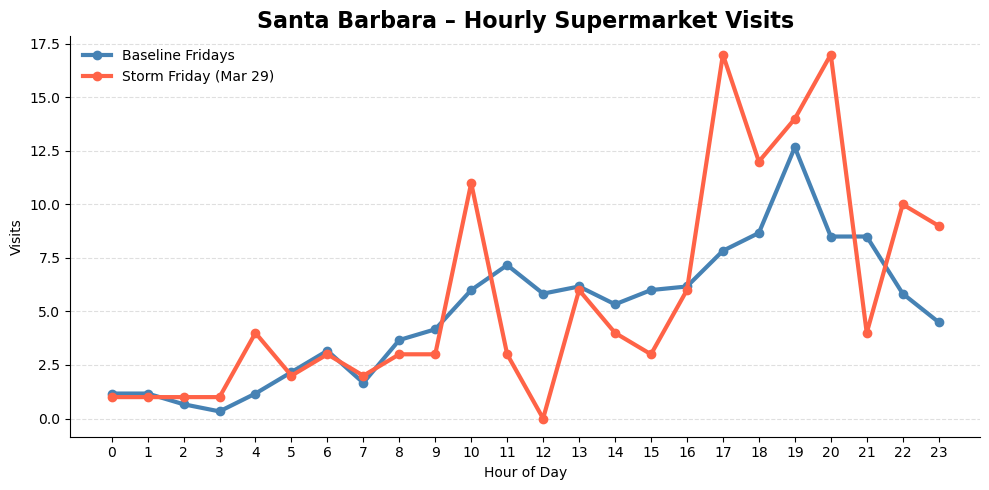

In [86]:
baseline_hourly_visits = (
    baseline_sb.groupby("hour")["uid"].count() / baseline_sb["day"].nunique()
).reindex(range(24), fill_value=0)

storm_hourly_visits = (
    storm_sb.groupby("hour")["uid"].count()
).reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    baseline_hourly_visits.index,
    baseline_hourly_visits.values,
    linewidth=3,
    marker="o",
    label="Baseline Fridays",
    color="steelblue"
)

ax.plot(
    storm_hourly_visits.index,
    storm_hourly_visits.values,
    linewidth=3,
    marker="o",
    label="Storm Friday (Mar 29)",
    color="tomato"
)

ax.set_title("Santa Barbara – Hourly Supermarket Visits", fontsize=16, weight="bold")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Visits")
ax.set_xticks(range(24))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

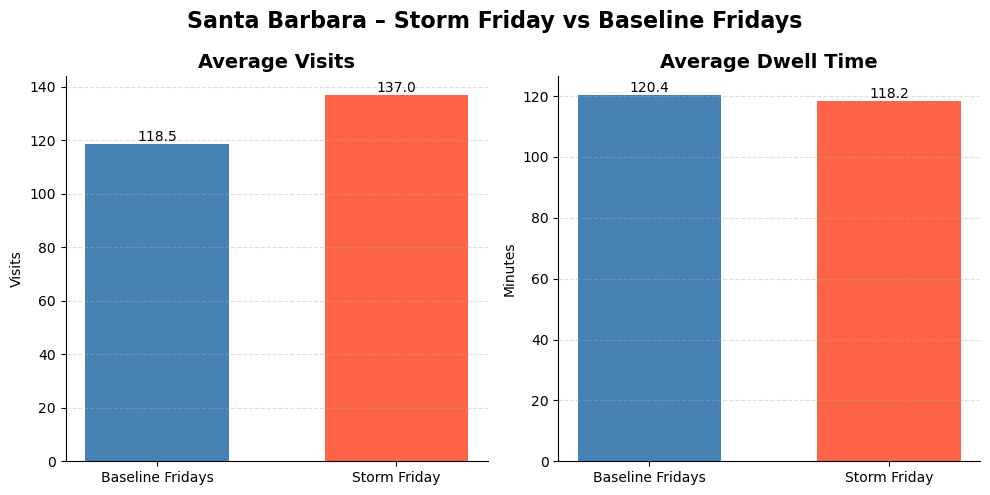

In [87]:
summary_df = pd.DataFrame({
    "group": ["Baseline Fridays", "Storm Friday"],
    "visits": [
        len(baseline_sb) / baseline_sb["day"].nunique(),
        len(storm_sb)
    ],
    "avg_dwell_min": [
        baseline_sb["duration_min"].mean(),
        storm_sb["duration_min"].mean()
    ]
})

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].bar(summary_df["group"], summary_df["visits"], color=["steelblue", "tomato"], width=0.6)
axes[0].set_title("Average Visits", fontsize=14, weight="bold")
axes[0].set_ylabel("Visits")
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

for i, v in enumerate(summary_df["visits"]):
    axes[0].text(i, v, f"{v:.1f}", ha="center", va="bottom")

axes[1].bar(summary_df["group"], summary_df["avg_dwell_min"], color=["steelblue", "tomato"], width=0.6)
axes[1].set_title("Average Dwell Time", fontsize=14, weight="bold")
axes[1].set_ylabel("Minutes")
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

for i, v in enumerate(summary_df["avg_dwell_min"]):
    axes[1].text(i, v, f"{v:.1f}", ha="center", va="bottom")

fig.suptitle("Santa Barbara – Storm Friday vs Baseline Fridays", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

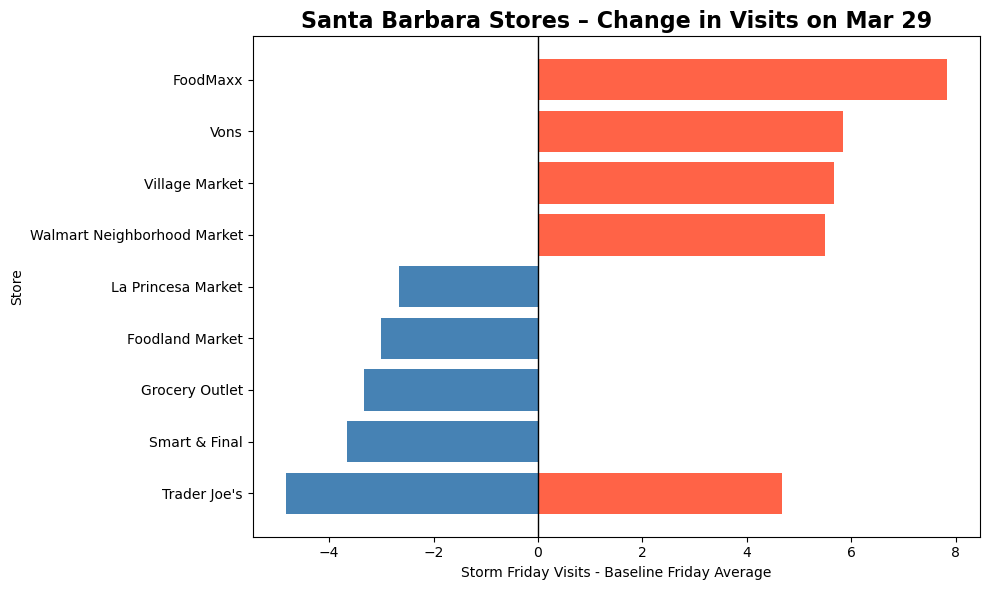

In [88]:
storm_counts = (
    storm_sb.groupby(["poi_id", "name", "poi_lat", "poi_lon"])
    .size()
    .rename("storm_visits")
)

baseline_counts = (
    baseline_sb.groupby(["poi_id", "name", "poi_lat", "poi_lon"])
    .size()
    .rename("baseline_total")
)

n_baseline_days = baseline_sb["day"].nunique()

poi_compare = pd.concat([storm_counts, baseline_counts], axis=1).fillna(0)
poi_compare["baseline_avg"] = poi_compare["baseline_total"] / n_baseline_days
poi_compare["diff"] = poi_compare["storm_visits"] - poi_compare["baseline_avg"]
poi_compare = poi_compare.reset_index()

top_inc = poi_compare.sort_values("diff", ascending=False).head(5).copy()
top_dec = poi_compare.sort_values("diff", ascending=True).head(5).copy()

plot_df = pd.concat([top_inc, top_dec]).drop_duplicates(subset=["poi_id"]).sort_values("diff")
colors = ["steelblue" if x < 0 else "tomato" for x in plot_df["diff"]]

plt.figure(figsize=(10, 6))
plt.barh(plot_df["name"].fillna(plot_df["poi_id"]), plot_df["diff"], color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.title("Santa Barbara Stores – Change in Visits on Mar 29", fontsize=16, weight="bold")
plt.xlabel("Storm Friday Visits - Baseline Friday Average")
plt.ylabel("Store")
plt.tight_layout()
plt.show()

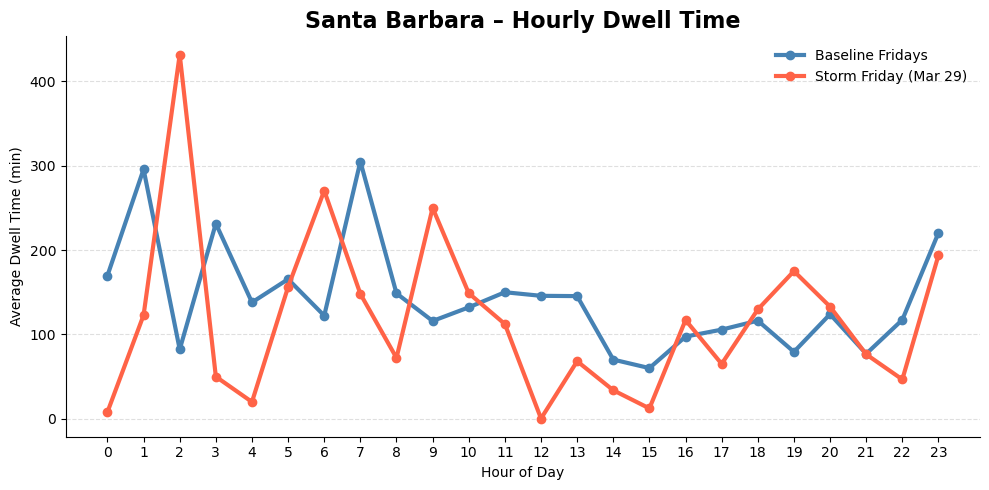

In [89]:
baseline_hourly_dwell = (
    baseline_sb.groupby("hour")["duration_min"].mean()
).reindex(range(24), fill_value=0)

storm_hourly_dwell = (
    storm_sb.groupby("hour")["duration_min"].mean()
).reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    baseline_hourly_dwell.index,
    baseline_hourly_dwell.values,
    linewidth=3,
    marker="o",
    label="Baseline Fridays",
    color="steelblue"
)

ax.plot(
    storm_hourly_dwell.index,
    storm_hourly_dwell.values,
    linewidth=3,
    marker="o",
    label="Storm Friday (Mar 29)",
    color="tomato"
)

ax.set_title("Santa Barbara – Hourly Dwell Time", fontsize=16, weight="bold")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Dwell Time (min)")
ax.set_xticks(range(24))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

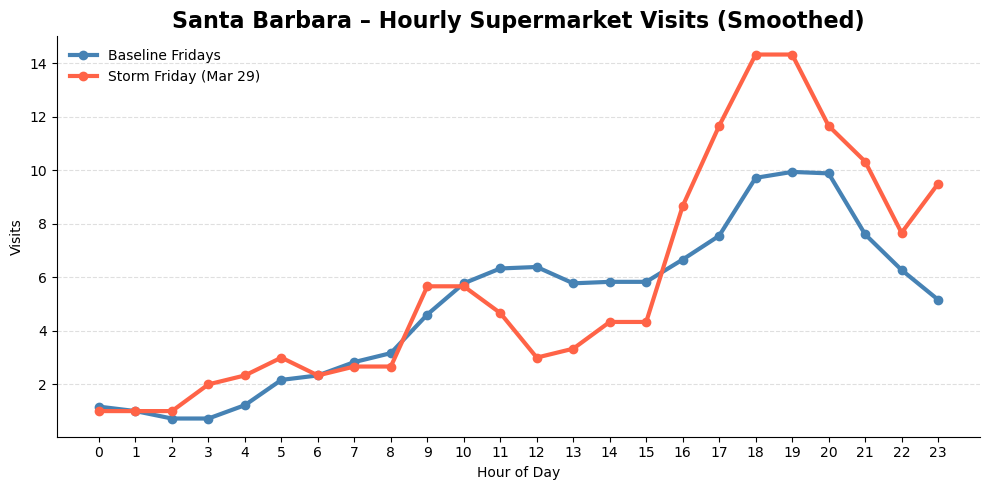

In [90]:
baseline_hourly_visits_smooth = baseline_hourly_visits.rolling(3, center=True, min_periods=1).mean()
storm_hourly_visits_smooth = storm_hourly_visits.rolling(3, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(baseline_hourly_visits_smooth.index, baseline_hourly_visits_smooth.values,
        linewidth=3, marker="o", color="steelblue", label="Baseline Fridays")
ax.plot(storm_hourly_visits_smooth.index, storm_hourly_visits_smooth.values,
        linewidth=3, marker="o", color="tomato", label="Storm Friday (Mar 29)")

ax.set_title("Santa Barbara – Hourly Supermarket Visits (Smoothed)", fontsize=16, weight="bold")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Visits")
ax.set_xticks(range(24))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [91]:
storm_day = pd.Timestamp("2024-03-30")

def hourly_plot_by_county(df, county_name=None):
    d = df.copy()
    
    if county_name:
        d = d[d["county"] == county_name]
    
    # Saturdays only
    sats = d[d["day"].dt.weekday == 5]
    
    storm = sats[sats["day"] == storm_day]
    baseline = sats[sats["day"] != storm_day]
    
    baseline_hour = (
        baseline.groupby("hour")["uid"].count() / baseline["day"].nunique()
    ).reindex(range(24), fill_value=0)
    
    storm_hour = (
        storm.groupby("hour")["uid"].count()
    ).reindex(range(24), fill_value=0)
    
    # smooth
    baseline_hour = baseline_hour.rolling(3, center=True, min_periods=1).mean()
    storm_hour = storm_hour.rolling(3, center=True, min_periods=1).mean()
    
    return baseline_hour, storm_hour

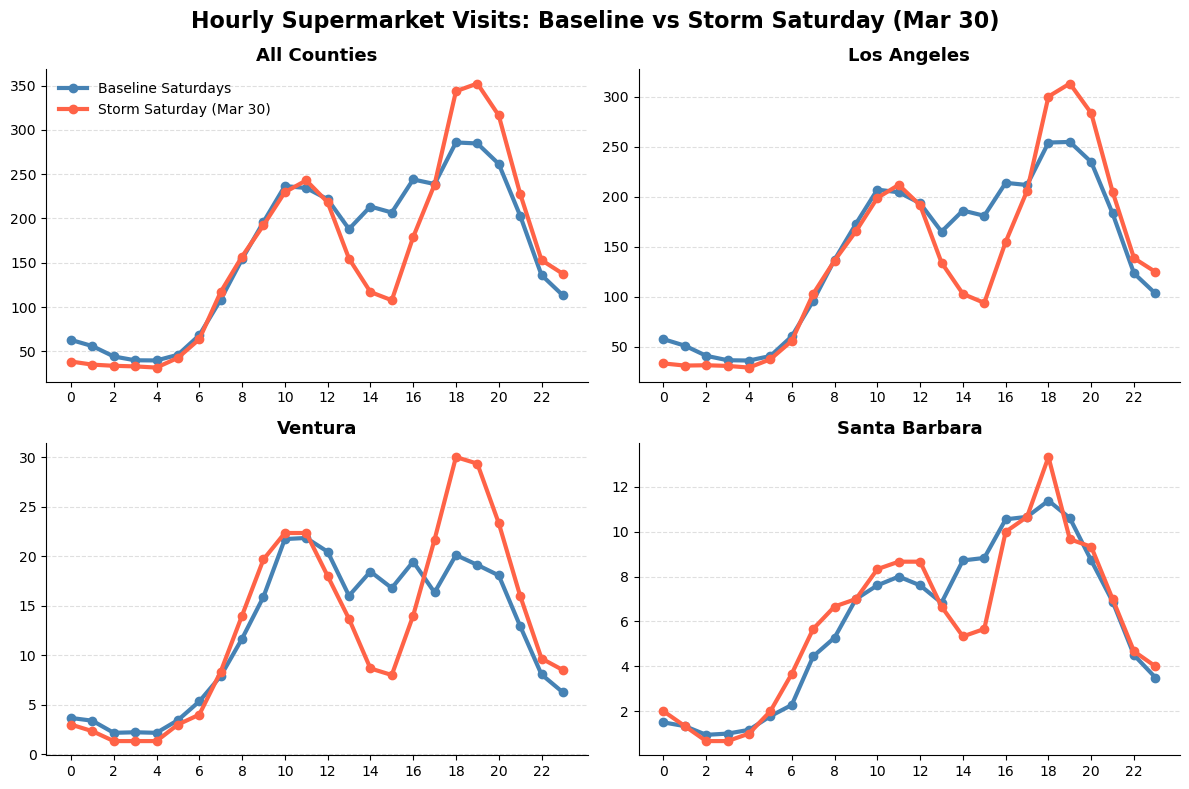

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

counties = [None, "Los Angeles", "Ventura", "Santa Barbara"]
titles = ["All Counties", "Los Angeles", "Ventura", "Santa Barbara"]

for ax, county, title in zip(axes.flatten(), counties, titles):
    
    b, s = hourly_plot_by_county(matched_named, county)
    
    ax.plot(b.index, b.values, color="steelblue", linewidth=3, marker="o", label="Baseline Saturdays")
    ax.plot(s.index, s.values, color="tomato", linewidth=3, marker="o", label="Storm Saturday (Mar 30)")
    
    ax.set_title(title, fontsize=13, weight="bold")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0,0].legend(frameon=False)

fig.suptitle("Hourly Supermarket Visits: Baseline vs Storm Saturday (Mar 30)", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()

In [93]:
storm_day = pd.Timestamp("2024-03-30")

def hourly_dwell_by_county(df, county_name=None):
    d = df.copy()
    
    if county_name:
        d = d[d["county"] == county_name]
    
    sats = d[d["day"].dt.weekday == 5]
    
    storm = sats[sats["day"] == storm_day]
    baseline = sats[sats["day"] != storm_day]
    
    baseline_hour = (
        baseline.groupby("hour")["duration_min"].mean()
    ).reindex(range(24), fill_value=0)
    
    storm_hour = (
        storm.groupby("hour")["duration_min"].mean()
    ).reindex(range(24), fill_value=0)
    
    # smooth
    baseline_hour = baseline_hour.rolling(3, center=True, min_periods=1).mean()
    storm_hour = storm_hour.rolling(3, center=True, min_periods=1).mean()
    
    return baseline_hour, storm_hour

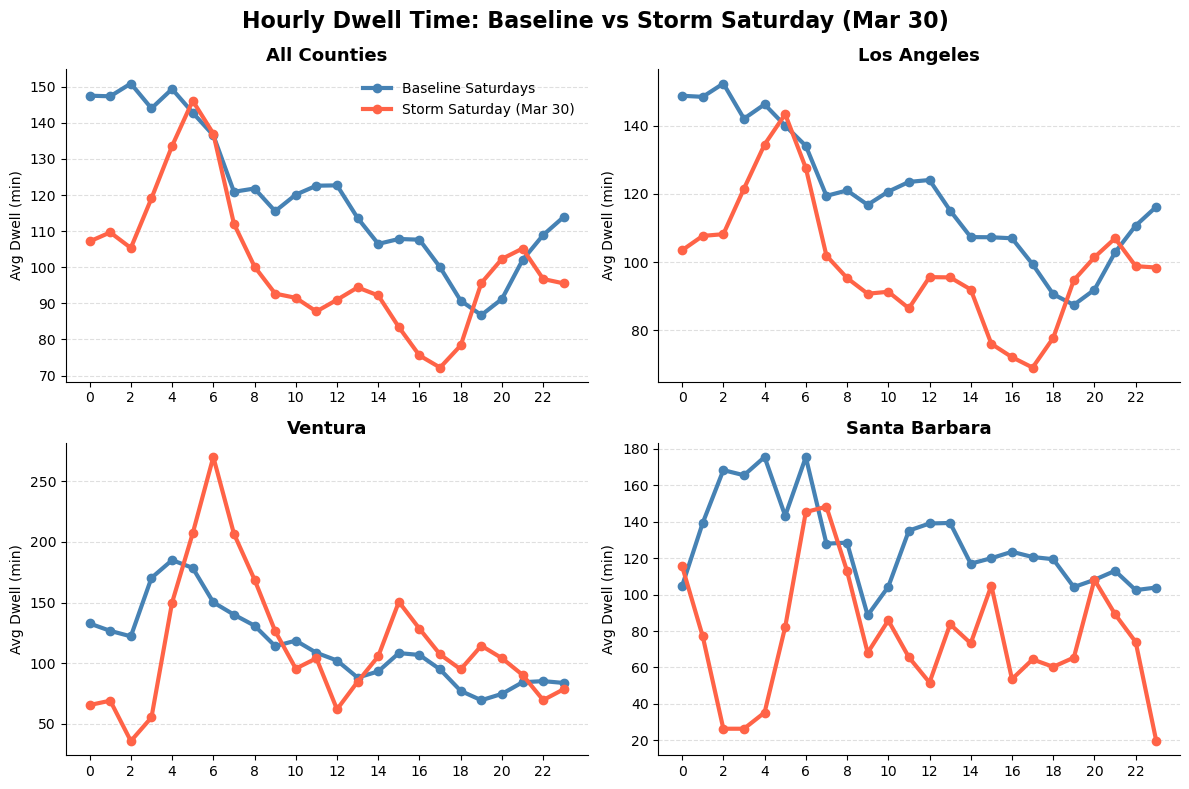

In [94]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

counties = [None, "Los Angeles", "Ventura", "Santa Barbara"]
titles = ["All Counties", "Los Angeles", "Ventura", "Santa Barbara"]

for ax, county, title in zip(axes.flatten(), counties, titles):
    
    b, s = hourly_dwell_by_county(matched_named, county)
    
    ax.plot(b.index, b.values, color="steelblue", linewidth=3, marker="o", label="Baseline Saturdays")
    ax.plot(s.index, s.values, color="tomato", linewidth=3, marker="o", label="Storm Saturday (Mar 30)")
    
    ax.set_title(title, fontsize=13, weight="bold")
    ax.set_xticks(range(0, 24, 2))
    ax.set_ylabel("Avg Dwell (min)")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0,0].legend(frameon=False)

fig.suptitle("Hourly Dwell Time: Baseline vs Storm Saturday (Mar 30)", fontsize=16, weight="bold")
plt.tight_layout()
plt.show()